In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from astropy.coordinates import SkyCoord
import astropy.units as u
import astropy.constants as cons
from astropy.visualization.wcsaxes import SphericalCircle

from sklearn.neighbors import KernelDensity

In [3]:
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=67.3, Om0=0.27, Tcmb0=2.725)

In [4]:
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import rc, rcParams
f = 0.8

fontsize = 35 * f
labelsize = 20 * f

rc("xtick", labelsize=fontsize * f)
rc("ytick", labelsize=fontsize * f)
rcParams["axes.linewidth"] = 5.3 * f
rcParams["xtick.major.width"] = 5.3 * f
rcParams["xtick.minor.width"] = 5.3 * f
rcParams["ytick.major.width"] = 5.3 * f
rcParams["ytick.minor.width"] = 5.3 * f
rcParams["xtick.major.size"] = 12.5 * f
rcParams["xtick.minor.size"] = 6.5 * f
rcParams["ytick.major.size"] = 12.5 * f
rcParams["ytick.minor.size"] = 6.5 * f

font = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 50 * f,
        }


cm1 = plt.cm.get_cmap('jet')
cm2 = plt.cm.get_cmap('rainbow')
cm3 = plt.cm.get_cmap('gnuplot2')
cm4 = plt.cm.get_cmap('Pastel2')
cm5 = plt.cm.get_cmap('Set3')
cm6 = plt.cm.get_cmap('gist_rainbow')

color_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
colors1 = [cm1(value) for value in color_values]
colors2 = [cm2(value) for value in color_values]
colors3 = [cm3(value) for value in color_values]
colors4 = [cm4(value) for value in color_values]
colors5 = [cm5(value) for value in color_values]
colors6 = [cm6(value) for value in color_values]

/tmp/ipykernel_6950/1944463329.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cm1 = plt.cm.get_cmap('jet')
/tmp/ipykernel_6950/1944463329.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cm2 = plt.cm.get_cmap('rainbow')
/tmp/ipykernel_6950/1944463329.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cm3 = plt.cm.get_cmap('gnuplot2')
/tmp/ipykernel_6950/1944463329.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib

In [6]:
from galaxy_cluster_membership import *

### Load data

In [5]:
#Table stracted from N.M.Cardoso+2026

clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")

# clusters_properties

In [25]:
cl = 10
cl_name = clusters_properties["Cluster"][cl]
print(cl_name)

# cl_name = 'A1644'
# cl = np.argwhere(clusters_properties["Cluster"]==cl_name)[0][0]

t = pd.read_csv("tables/SCALE/clusters_v7_csv/"+cl_name+".csv")

# print(np.array(t.columns))

MKW4


/tmp/ipykernel_664056/638988371.py:8: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/clusters_v7_csv/"+cl_name+".csv")


In [27]:
z_cluster = clusters_properties["z"][cl]
r200_mpc = clusters_properties["R200"][cl]
zp_bias = float(clusters_properties["off"][cl])

kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

5*r200_deg

/home/elismar/miniconda3/envs/Doc/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3577: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will stop working in a future release. Pass it positionally to suppress this warning.
  exec(code_obj, self.user_global_ns, self.user_ns)


np.float64(3.68473317966086)

In [7]:
#PROPERTIES OF GALAXIES
r_PStotal = t["r_PStotal"].values
mask_good = ~np.isnan(r_PStotal)
t_good = t[mask_good]

ras = t_good["ra"].values
decs = t_good["dec"].values
zphot = t_good["zml"].values
z = t_good["z"].values
r_PStotal = t_good["r_PStotal"].values

pdf_weights = np.array([t_good[col_name] for col_name in ["pdf_weights_" + str(i) for i in range(0, 3)]])
pdf_means = np.array([t_good[col_name] for col_name in ["pdf_means_" + str(i) for i in range(0, 3)]])
pdf_stds = np.array([t_good[col_name] for col_name in ["pdf_stds_" + str(i) for i in range(0, 3)]])

members = t_good["flag_member"] == 0


#PROPERTIES OF THE CLUSTER
ra0 = clusters_properties["R.A."][cl]
dec0 = clusters_properties["Dec."][cl]
z_cluster = clusters_properties["z"][cl]
r200_mpc = clusters_properties["R200"][cl]
zp_bias = float(clusters_properties["off"][cl])

kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

print("Cluster redshift: ", z_cluster)

Cluster redshift:  0.02


/home/elismar/miniconda3/envs/Doc/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3577: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will stop working in a future release. Pass it positionally to suppress this warning.
  exec(code_obj, self.user_global_ns, self.user_ns)


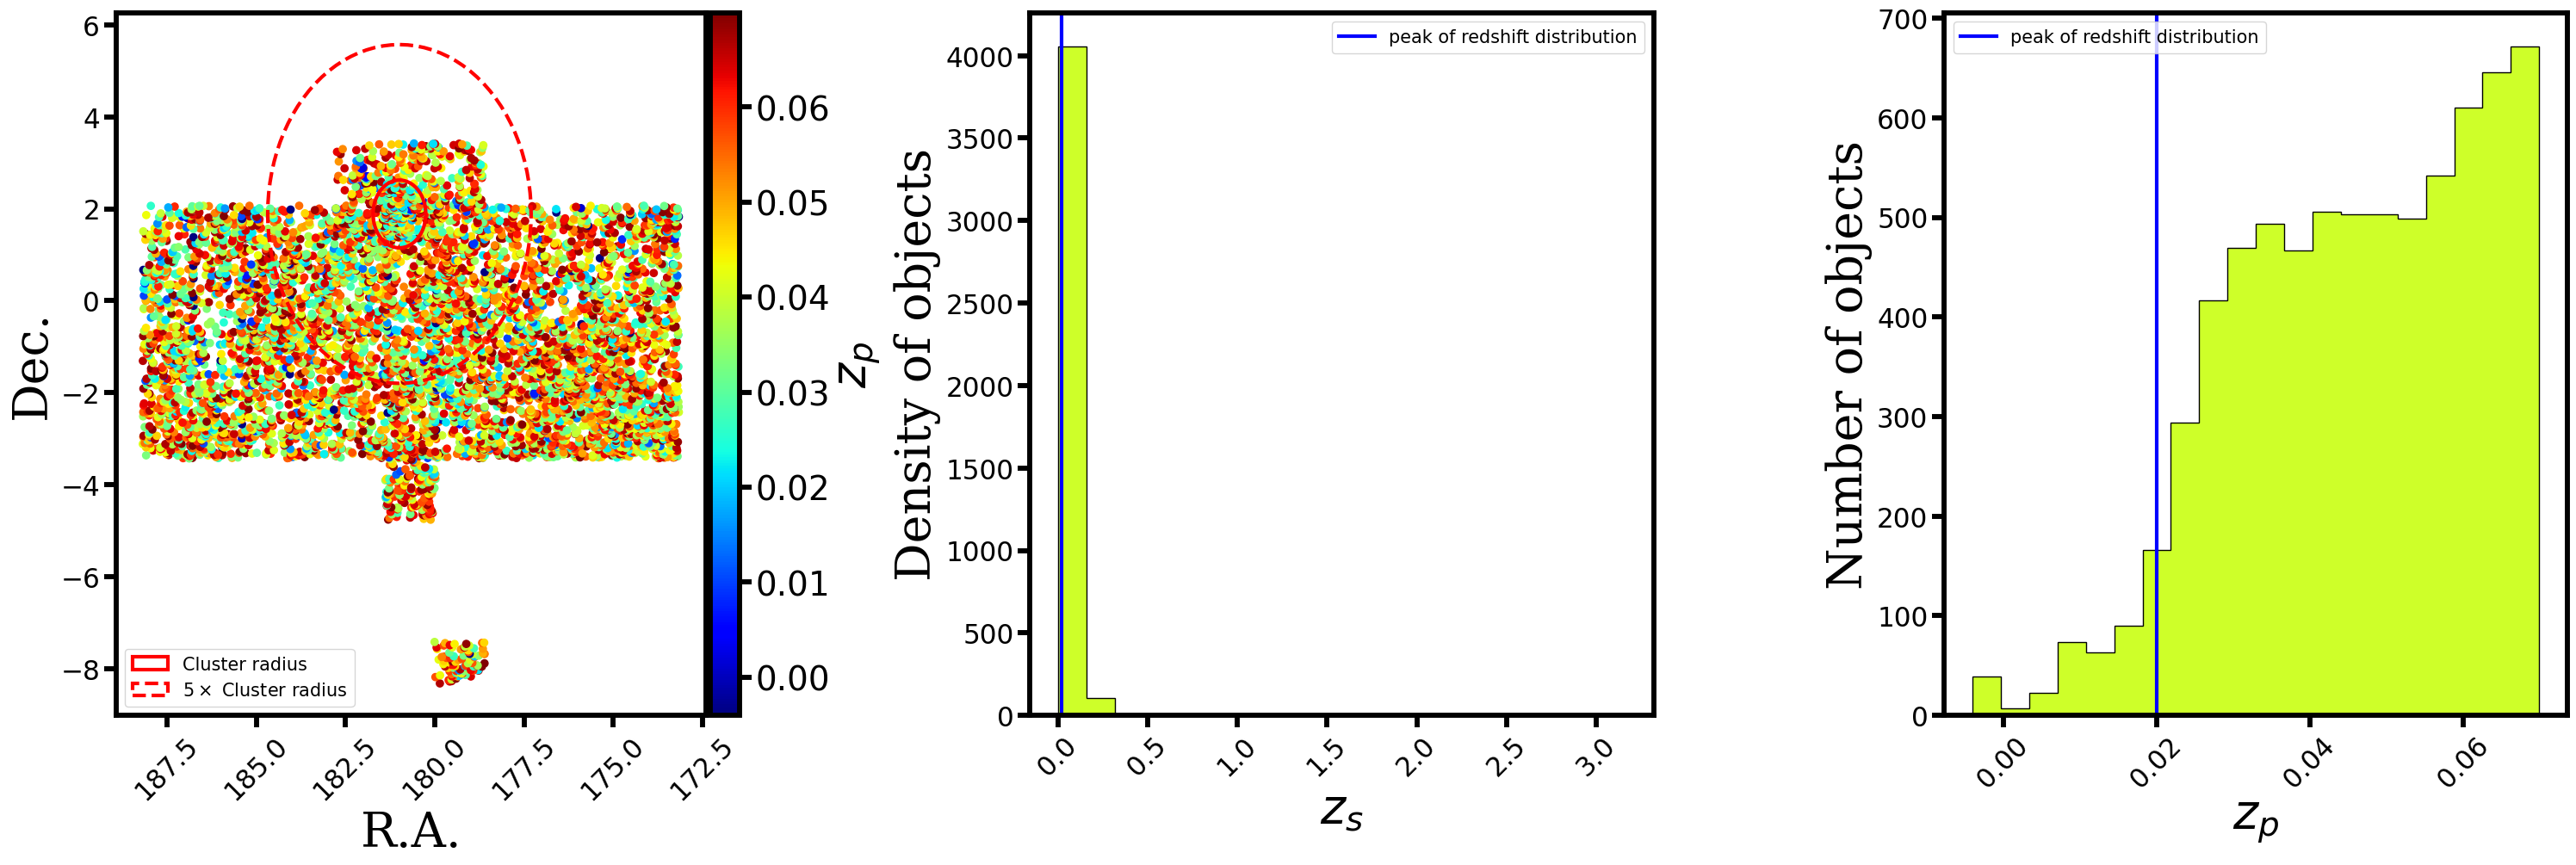

In [15]:
z_bins = 20
fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(30, 10))
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]

#Plot spatial distribution
sc = ax1.scatter(ras, decs, c=zphot, cmap=cm1)
# ax1.scatter(ra0, dec0, marker="X", s=100, color="red", label="Cluster center")

ax1.set_xlabel("R.A.", fontdict=font)
ax1.set_ylabel("Dec.", fontdict=font)
ax1.tick_params(axis='x', rotation=45)

# ax1.text(ra0+2*r200_deg, dec0+2*r200_deg, s=r"$RA_0 = {:.2f}$".format(ra0), fontsize=15)
# ax1.text(ra0+2*r200_deg, dec0+1.8*r200_deg, s=r"$Dec_0 = {:.2f}$".format(dec0), fontsize=15)
# ax1.text(ra0+2*r200_deg, dec0+1.6*r200_deg, s=r"$z_C = {:.2f}$".format(z_cluster), fontsize=15)
# ax1.text(ra0+2*r200_deg, dec0+1.4*r200_deg, s=r"$m200 = {:.2f} (1e15 Msun/h)$".format(m200.value/1e15), fontsize=15)
# ax1.text(ra0+2*r200_deg, dec0+1.2*r200_deg, s=r"$r200 = {:.2f}º = {:.2f} Mpc$".format(r200_deg, r200_mpc.value), fontsize=15)

c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=3, label="Cluster radius", edgecolor="red", facecolor="None")
ax1.add_patch(r1)
r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=3, label=r"$5 \times$ Cluster radius", edgecolor="red", facecolor="None", ls='--')
ax1.add_patch(r2)

divider = make_axes_locatable(ax1)
cax1 = divider.append_axes('right', size='5%', pad=0.05)
cbar = fig.colorbar(sc, cax=cax1, orientation='vertical')
cbar.set_label(label=r"$z_p$", fontdict=font)
cbar.ax.tick_params(labelsize=labelsize)

ax1.invert_xaxis()
ax1.legend(fontsize=15)


#Distribution of spec-zs of cluster galaxies
hist = ax2.hist(z[~np.isnan(z)], bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k', range=[z[~np.isnan(z)].min(), z[~np.isnan(z)].max()])[0]
ax2.set_xlabel("z_spec", fontdict=font)
ax2.set_ylabel("Number of objects", fontdict=font)
ax2.tick_params(axis='x', rotation=45)

# f = hist[np.argmax(hist)] / np.exp(log_dens_zz)[np.argmax(np.exp(log_dens_zz))]
# ax2.plot(zz, np.exp(log_dens_zz)*f, lw=4, color=colors1[8], label="KDE estimation")
ax2.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
ax2.set_xlabel(r"$z_s$", fontdict=font)
ax2.set_ylabel("Density of objects", fontdict=font)
ax2.tick_params(axis='x', rotation=45)
ax2.legend(fontsize=15)


#Distribution of photo-zs of cluster galaxies
ax3.hist(zphot[~np.isnan(zphot)], bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k')[2]
ax3.set_xlabel(r"$z_p$", fontdict=font)
ax3.set_ylabel("Number of objects", fontdict=font)
ax3.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
ax3.tick_params(axis='x', rotation=45)
ax3.legend(fontsize=15)


fig.tight_layout(pad=1.0)

### Membership

##### Elocubrações sobre magnitude r_auto vs r_PStotal

Text(0, 0.5, 'r_auto')

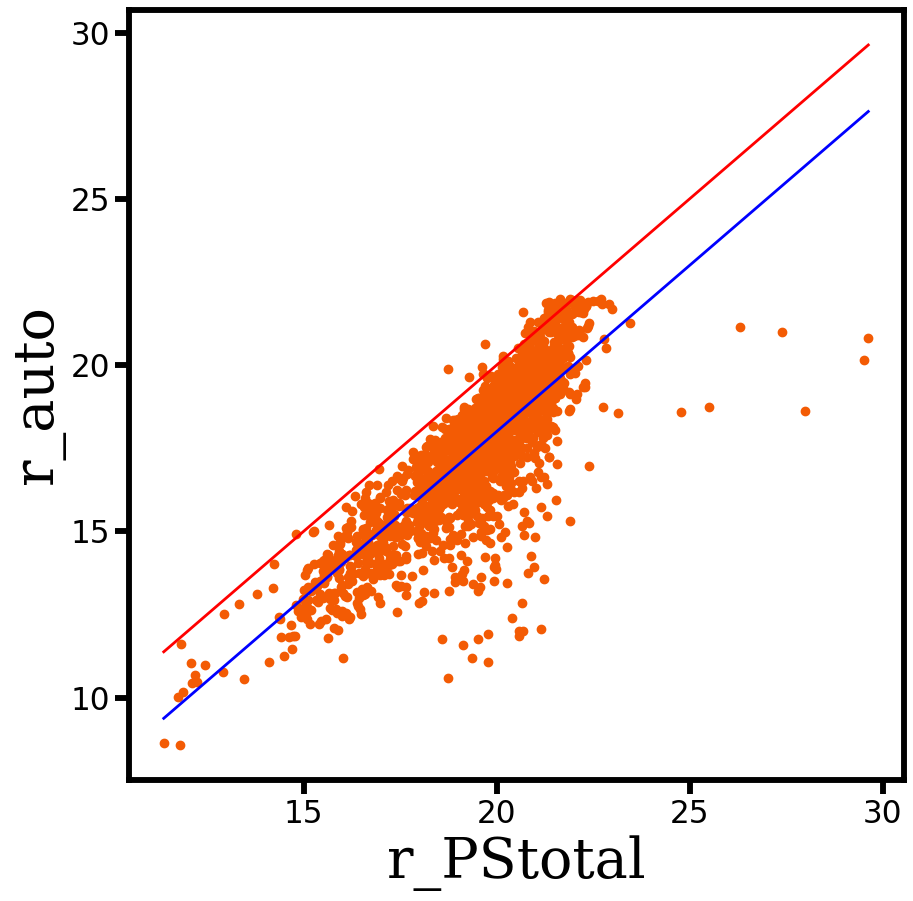

In [108]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)

sc = ax.scatter(t["r_PStotal"].values, t["r_auto"].values, c="#f35b04")
ax.plot([t["r_PStotal"].values[mask_good].min(), t["r_PStotal"].values[mask_good].max()], [t["r_PStotal"].values[mask_good].min(), t["r_PStotal"].values[mask_good].max()],
         lw=2, color="red", label="1:1 line")
ax.plot([t["r_PStotal"].values[mask_good].min(), t["r_PStotal"].values[mask_good].max()], [t["r_PStotal"].values[mask_good].min()-2, t["r_PStotal"].values[mask_good].max()-2],
         lw=2, color="blue", label="1:1 line")
ax.set_xlabel("r_PStotal", fontdict=font)
ax.set_ylabel("r_auto", fontdict=font)

/tmp/ipykernel_457578/3208348448.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=15)


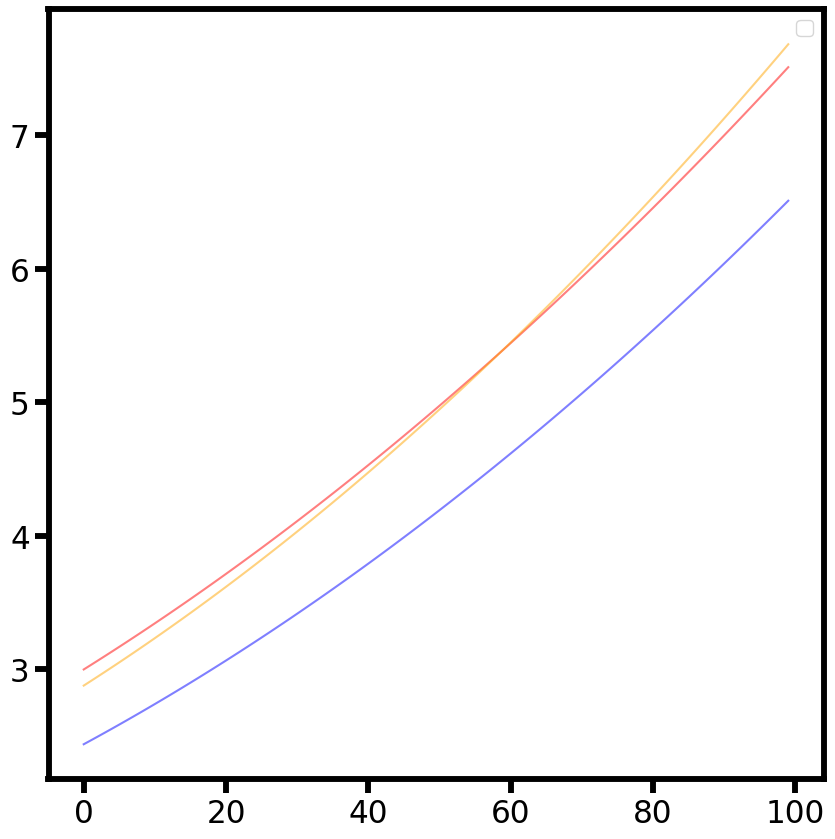

In [134]:
x1 = np.linspace(10, 21, 100)
x2 = x1 - 2

y1 = 0.01*x1**2 + 0.1*x1 + 1
y2 = 0.01*x2**2 + 0.1*x2 + 1

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)

ax.plot(y1, c="red", alpha=0.5)
ax.plot(y2, c="blue", alpha=0.5)

ax.plot(y2*1.18, c="orange", alpha=0.5)

ax.legend(fontsize=15)

#### Voltando

In [ ]:
#Vamos usar o r_PStotal na magnitude do membership, que é a mesma magnitude que eu usei pra modelar o sigma_nmad(r).

f = 1.5
fr = 5

sigma_z = np.array([sigma_nmad_(r) for r in r_PStotal])

dist = clustercentric_distance(ras, decs, ra0, dec0)
mask_cluster_region = (dist < fr*r200_deg)

mask_cluster = mask_cluster_region & (zphot > z_cluster - f*sigma_z*(1+z_cluster)) & (zphot < z_cluster + f*sigma_z*(1+z_cluster))

In [17]:
#Compute photo-z bias and remove it from the photo-zs, redefining the mask_cluster
z_bins = 20
bw = (zphot[mask_cluster].max() - zphot[mask_cluster].min()) / z_bins

kde = KernelDensity(kernel="gaussian", bandwidth=bw).fit(zphot[mask_cluster][:, np.newaxis])
zz_phot = np.linspace(zphot[mask_cluster].min(), zphot[mask_cluster].max(), len(zphot[mask_cluster]))[:, np.newaxis]
log_dens_zz_phot = kde.score_samples(zz_phot)

zp_peak = zz_phot[np.argmax(np.exp(log_dens_zz_phot))]
zp_bias_mine = zp_peak - z_cluster

zphot_unbiased = zphot - zp_bias_mine

mask_cluster_unbiased =  (zphot_unbiased[mask_cluster_region] > z_cluster - f*sigma_z[mask_cluster_region]*(1+z_cluster)) & (
                        zphot_unbiased[mask_cluster_region] < z_cluster + f*sigma_z[mask_cluster_region]*(1+z_cluster))

print("zp_bias = {}".format(zp_bias_mine))

print("zp_bias from Paulo= {}".format(zp_bias))

zp_bias = [0.01346427]
zp_bias from Paulo= 0.0047


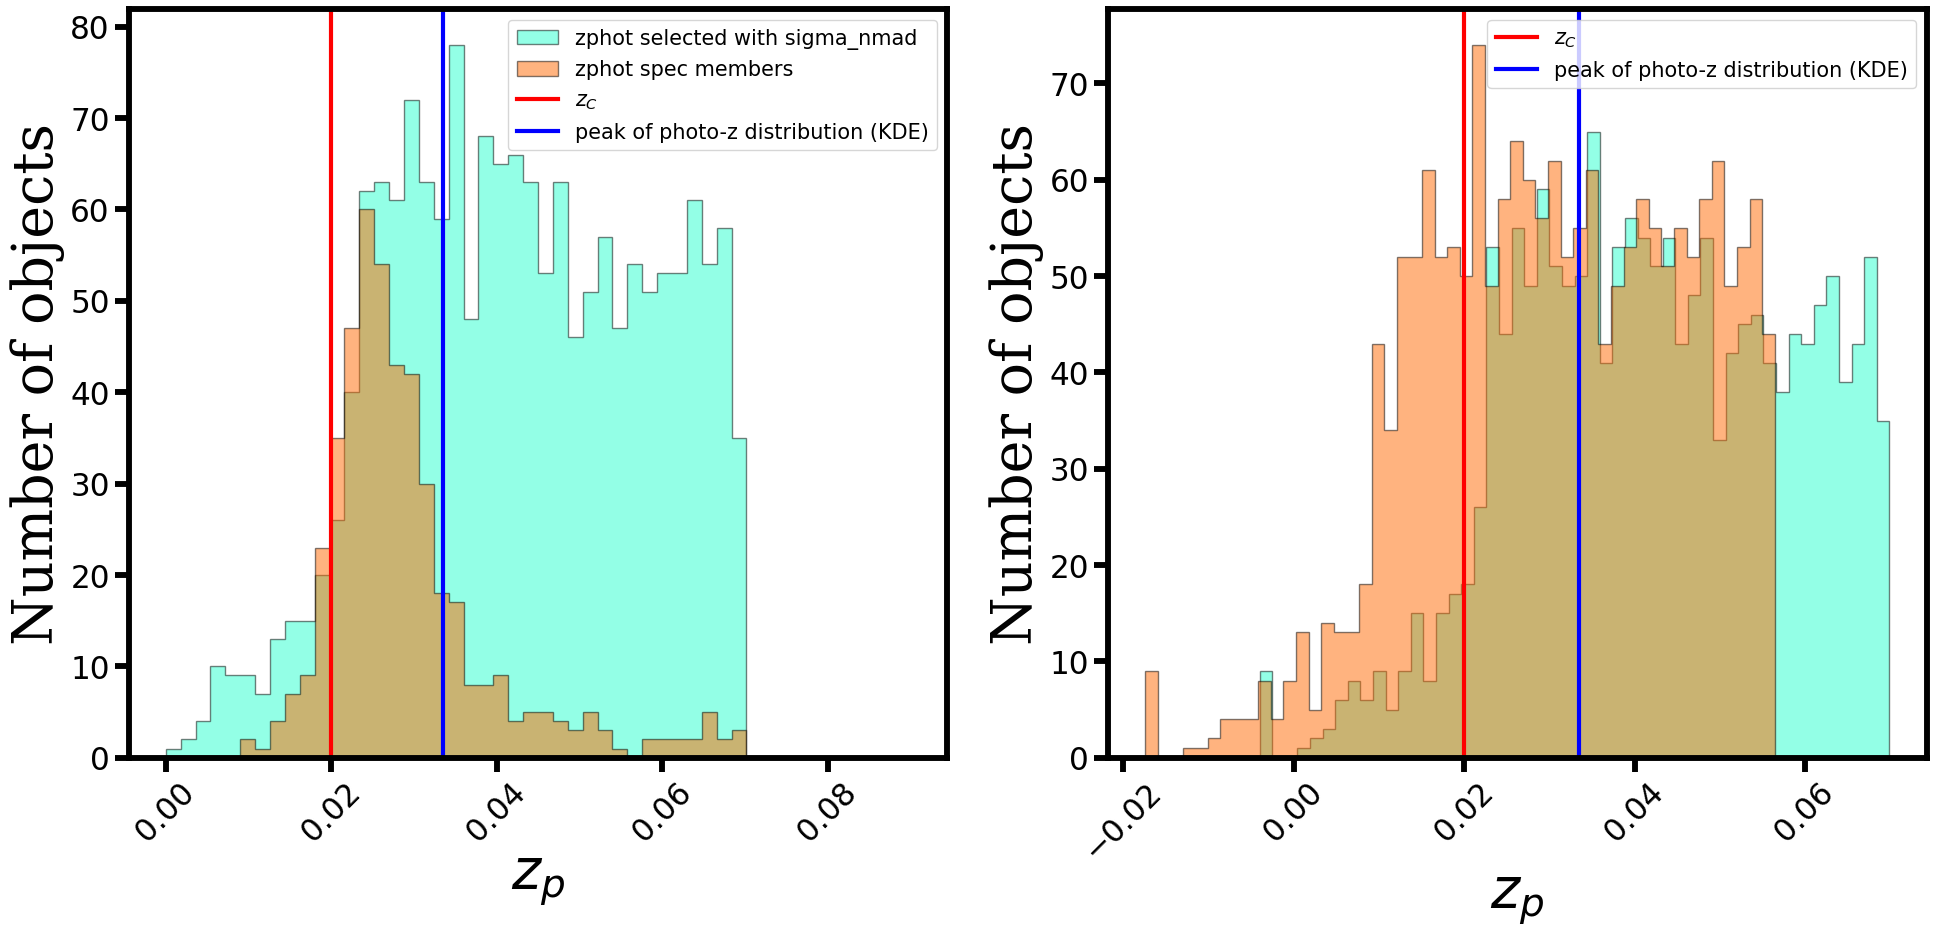

In [20]:
fig = plt.figure(figsize=(20, 10))
ax1 = fig.add_subplot(121)
ax3 = fig.add_subplot(122)

ax1.hist(zphot[mask_cluster], bins=50, color=colors1[3], histtype='stepfilled', edgecolor='k', 
         alpha=0.5, range=[0, 0.09], label="zphot selected with sigma_nmad")[2]
ax1.hist(zphot[members], bins=50, color=colors1[7], histtype='stepfilled', edgecolor='k', 
         alpha=0.5, range=[0, 0.09], label="zphot spec members")[2]
ax1.set_xlabel(r"$z_p$", fontdict=font)
ax1.set_ylabel("Number of objects", fontdict=font)
ax1.axvline(z_cluster, color="red", lw=3, label=r"$z_C$")
ax1.axvline(zp_peak, color="blue", lw=3, label="peak of photo-z distribution (KDE)")
ax1.tick_params(axis='x', rotation=45)
ax1.legend(fontsize=15)

ax3.hist(zphot[mask_cluster], bins=50, color=colors1[3], histtype='stepfilled', edgecolor='k', alpha=0.5)[2]
ax3.hist(zphot_unbiased[mask_cluster_region][mask_cluster_unbiased], bins=50, color=colors1[7], histtype='stepfilled', edgecolor='k', alpha=0.5)[2]
ax3.set_xlabel(r"$z_p$", fontdict=font)
ax3.set_ylabel("Number of objects", fontdict=font)
ax3.axvline(z_cluster, color="red", lw=3, label=r"$z_C$")
ax3.axvline(zp_peak, color="blue", lw=3, label="peak of photo-z distribution (KDE)")
ax3.tick_params(axis='x', rotation=45)
ax3.legend(fontsize=15)

fig.tight_layout(pad=3.0)

In [21]:
Pmem = P_pz_v2(z_cluster, 
                sigma_z[mask_cluster_region],
                pdf_means.T[mask_cluster_region], 
                pdf_weights.T[mask_cluster_region], 
                pdf_stds.T[mask_cluster_region], 
                fz=f)

/home/elismar/Doc/galaxy-cluster-membership/galaxy_cluster_membership.py:334: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  P_pz_C = integrate.quad(pdfs_interp, 0.0, zc + fz*sigma_i*(1+zc))[0]
/home/elismar/Doc/galaxy-cluster-membership/galaxy_cluster_membership.py:337: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  P_pz_C = integrate.quad(pdfs_interp, zc - fz*sigma_i*(1+zc), zc + fz*sigma_i*(1+zc))[0]
/home/elismar/Doc/galaxy-cluster-membership/galaxy_cluster_m

In [22]:
phot_members_mask = mask_cluster_unbiased & (Pmem > 0.5)

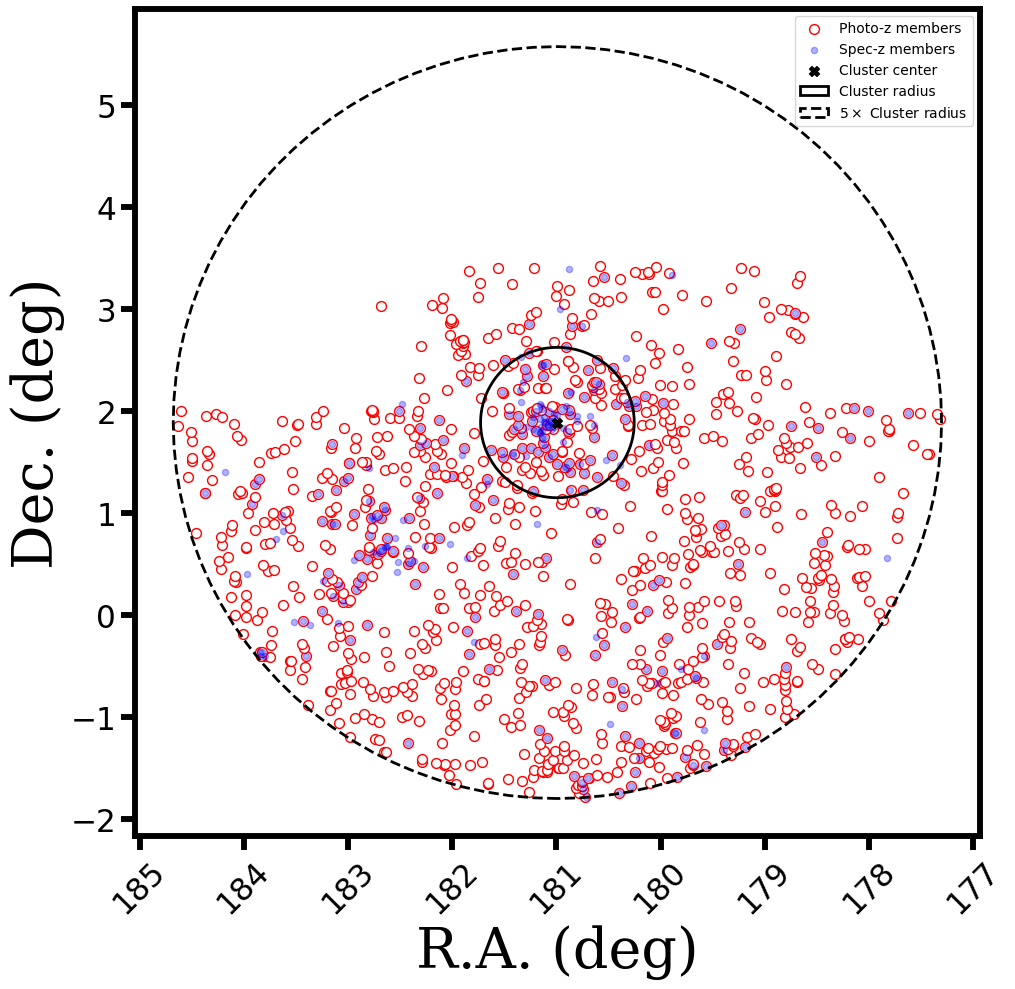

In [23]:
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(111)

ax1.scatter(ras[mask_cluster_region][phot_members_mask], decs[mask_cluster_region][phot_members_mask], 
            c="white", s=50, edgecolor="red", label=r"Photo-z members")

ax1.scatter(ras[members & (dist<fr*r200_deg)], decs[members & (dist<fr*r200_deg)], c="blue", s=20, 
            alpha=0.3, label=r"Spec-z members")

ax1.set_xlabel("R.A. (deg)", fontdict=font)
ax1.set_ylabel("Dec. (deg)", fontdict=font)
ax1.scatter(ra0, dec0, marker="X", s=50, color="k", label="Cluster center")

c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=2, label="Cluster radius", edgecolor="k", facecolor="None")
ax1.add_patch(r1)
r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=2, label=r"$5 \times$ Cluster radius", edgecolor="k", facecolor="None", ls='--')
ax1.add_patch(r2)

ax1.legend(fontsize=10)
ax1.tick_params(axis='x', rotation=45)
ax1.invert_xaxis()

fig.tight_layout()
# plt.savefig("../figures/membership-testing-on-mocks/23-07-2025/cluster_field_separation_P(C|zp)_mock{}.png".format(i_mock), dpi='figure', format='png')

In [24]:
# t = pd.read_csv("tables/splash+5r200/csv_tables/A4038_v7.csv")
    
# rauto = np.asarray(t["r_auto"])
# t2 = t[~np.isnan(rauto)]

mask_cluster_region_aux = np.isin(t.index, t_good[mask_cluster_region].index)

#Save original table with three new columns. We consider just the galaxies in the "mask_cluster_region". 
# Galaxies not in this region will have an empty value associated to these columns
t.loc[mask_cluster_region_aux, "R"] = dist[mask_cluster_region] / r200_deg 
t.loc[mask_cluster_region_aux, "Pmem_zp"] = Pmem

t.loc[mask_cluster_region_aux, "flag_member_photz1"] = ~phot_members_mask * 1  #(members = 0, interlopers = 1) #tá na lógica inversa do operador booleano do python
t.loc[~mask_cluster_region_aux, "flag_member_photz1"] = -1 #undetermined

t.to_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name), index=False)

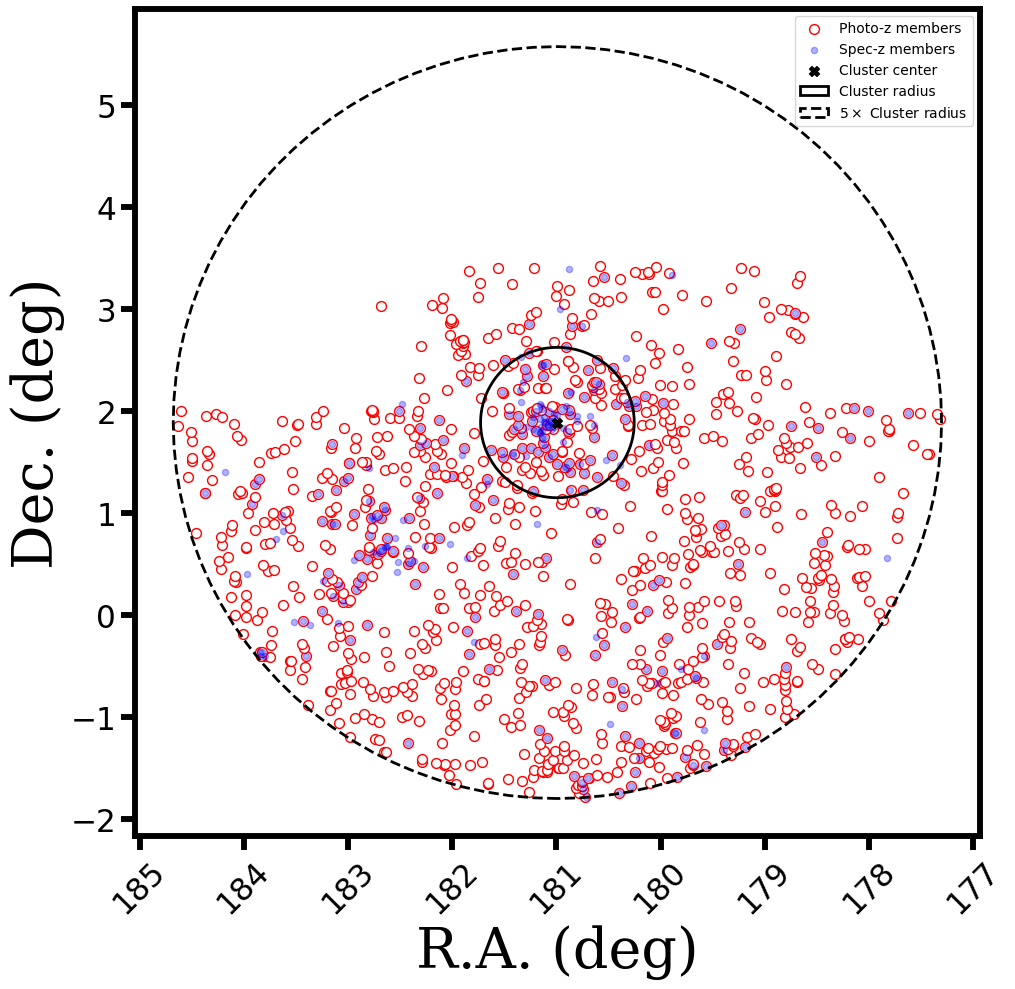

In [25]:
phot_members = t["flag_member_photz1"].values == 0
spec_members = t["flag_member"].values == 0

fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(111)

ax1.scatter(t["ra"][phot_members], t["dec"][phot_members], 
            c="white", s=50, edgecolor="red", label=r"Photo-z members")

ax1.scatter(t["ra"][spec_members & (t["R"]<5)], t["dec"][spec_members & (t["R"]<5)], c="blue", s=20, 
            alpha=0.3, label=r"Spec-z members")

ax1.set_xlabel("R.A. (deg)", fontdict=font)
ax1.set_ylabel("Dec. (deg)", fontdict=font)
ax1.scatter(ra0, dec0, marker="X", s=50, color="k", label="Cluster center")

c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=2, label="Cluster radius", edgecolor="k", facecolor="None")
ax1.add_patch(r1)
r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=2, label=r"$5 \times$ Cluster radius", edgecolor="k", facecolor="None", ls='--')
ax1.add_patch(r2)

ax1.legend(fontsize=10)
ax1.tick_params(axis='x', rotation=45)
ax1.invert_xaxis()

fig.tight_layout()

#### Run for every cluster with z> ~0.040

In [ ]:
f = 1.5
fr = 5

for cl in range(80, 84, 1):

    print("Running for cluster:", cl)

    cl_name = clusters_properties["Cluster"][cl]
    print(cl_name)

    # cl_name = 'A1644'
    # cl = np.argwhere(clusters_properties["Cluster"]==cl_name)[0][0]

    t = pd.read_csv("tables/SCALE/clusters_v7_csv/"+cl_name+".csv")

    #PROPERTIES OF GALAXIES
    r_PStotal = t["r_PStotal"].values
    mask_good = ~np.isnan(r_PStotal)
    t_good = t[mask_good]

    ras = t_good["ra"].values
    decs = t_good["dec"].values
    zphot = t_good["zml"].values
    z = t_good["z"].values
    r_PStotal = t_good["r_PStotal"].values

    pdf_weights = np.array([t_good[col_name] for col_name in ["pdf_weights_" + str(i) for i in range(0, 3)]])
    pdf_means = np.array([t_good[col_name] for col_name in ["pdf_means_" + str(i) for i in range(0, 3)]])
    pdf_stds = np.array([t_good[col_name] for col_name in ["pdf_stds_" + str(i) for i in range(0, 3)]])

    members = t_good["flag_member"] == 0


    #PROPERTIES OF THE CLUSTER
    ra0 = clusters_properties["R.A."][cl]
    dec0 = clusters_properties["Dec."][cl]
    z_cluster = clusters_properties["z"][cl]
    r200_mpc = clusters_properties["R200"][cl]
    # zp_bias = float(clusters_properties["off"][cl])

    kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
    r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

    print("Cluster redshift: ", z_cluster)

    z_bins = 20
    fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(30, 10))
    ax1 = axs[0]
    ax2 = axs[1]
    ax3 = axs[2]

    #Plot spatial distribution
    sc = ax1.scatter(ras, decs, c=zphot, cmap=cm1)
    # ax1.scatter(ra0, dec0, marker="X", s=100, color="red", label="Cluster center")

    ax1.set_xlabel("R.A.", fontdict=font)
    ax1.set_ylabel("Dec.", fontdict=font)
    ax1.tick_params(axis='x', rotation=45)

    c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
    r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=3, label="Cluster radius", edgecolor="red", facecolor="None")
    ax1.add_patch(r1)
    r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=3, label=r"$5 \times$ Cluster radius", edgecolor="red", facecolor="None", ls='--')
    ax1.add_patch(r2)

    divider = make_axes_locatable(ax1)
    cax1 = divider.append_axes('right', size='5%', pad=0.05)
    cbar = fig.colorbar(sc, cax=cax1, orientation='vertical')
    cbar.set_label(label=r"$z_p$", fontdict=font)
    cbar.ax.tick_params(labelsize=labelsize)

    ax1.invert_xaxis()
    ax1.legend(fontsize=15)


    #Distribution of spec-zs of cluster galaxies
    hist = ax2.hist(z[~np.isnan(z)], bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k', range=[z[~np.isnan(z)].min(), z[~np.isnan(z)].max()])[0]
    ax2.set_xlabel("z_spec", fontdict=font)
    ax2.set_ylabel("Number of objects", fontdict=font)
    ax2.tick_params(axis='x', rotation=45)

    # f = hist[np.argmax(hist)] / np.exp(log_dens_zz)[np.argmax(np.exp(log_dens_zz))]
    # ax2.plot(zz, np.exp(log_dens_zz)*f, lw=4, color=colors1[8], label="KDE estimation")
    ax2.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
    ax2.set_xlabel(r"$z_s$", fontdict=font)
    ax2.set_ylabel("Density of objects", fontdict=font)
    ax2.tick_params(axis='x', rotation=45)
    ax2.legend(fontsize=15)


    #Distribution of photo-zs of cluster galaxies
    ax3.hist(zphot[~np.isnan(zphot)], bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k')[2]
    ax3.set_xlabel(r"$z_p$", fontdict=font)
    ax3.set_ylabel("Number of objects", fontdict=font)
    ax3.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
    ax3.tick_params(axis='x', rotation=45)
    ax3.legend(fontsize=15)

    fig.tight_layout(pad=1.0)
    plt.savefig("../figures/SCALE/membership_05022026/RaxDec_z_zp_{}.png".format(cl_name), dpi='figure', format='png')


    sigma_z = np.array([sigma_nmad_(r) for r in r_PStotal])

    dist = clustercentric_distance(ras, decs, ra0, dec0)
    mask_cluster_region = (dist < fr*r200_deg)

    mask_cluster = mask_cluster_region & (zphot > z_cluster - f*sigma_z*(1+z_cluster)) & (zphot < z_cluster + f*sigma_z*(1+z_cluster))


    #Compute photo-z bias and remove it from the photo-zs, redefining the mask_cluster
    z_bins = 20
    bw = (zphot[mask_cluster].max() - zphot[mask_cluster].min()) / z_bins

    kde = KernelDensity(kernel="gaussian", bandwidth=bw).fit(zphot[mask_cluster][:, np.newaxis])
    zz_phot = np.linspace(zphot[mask_cluster].min(), zphot[mask_cluster].max(), len(zphot[mask_cluster]))[:, np.newaxis]
    log_dens_zz_phot = kde.score_samples(zz_phot)

    zp_peak = zz_phot[np.argmax(np.exp(log_dens_zz_phot))]
    zp_bias_mine = zp_peak - z_cluster

    zphot_unbiased = zphot - zp_bias_mine

    mask_cluster_unbiased =  (zphot_unbiased[mask_cluster_region] > z_cluster - f*sigma_z[mask_cluster_region]*(1+z_cluster)) & (
                            zphot_unbiased[mask_cluster_region] < z_cluster + f*sigma_z[mask_cluster_region]*(1+z_cluster))

    print("zp_bias = {}".format(zp_bias_mine))
    # print("zp_bias from Paulo= {}".format(zp_bias))


    fig = plt.figure(figsize=(20, 10))
    ax1 = fig.add_subplot(121)
    ax3 = fig.add_subplot(122)

    ax1.hist(zphot[mask_cluster], bins=50, color=colors1[3], histtype='stepfilled', edgecolor='k', 
            alpha=0.5, range=[zphot[mask_cluster].min(), zphot[mask_cluster].max()], label="zphot selected with sigma_nmad")[2]
    ax1.hist(zphot[members], bins=50, color=colors1[7], histtype='stepfilled', edgecolor='k', 
            alpha=0.5, range=[zphot[mask_cluster].min(), zphot[mask_cluster].max()], label="zphot spec members")[2]
    ax1.set_xlabel(r"$z_p$", fontdict=font)
    ax1.set_ylabel("Number of objects", fontdict=font)
    ax1.axvline(z_cluster, color="red", lw=3, label=r"$z_C$")
    ax1.axvline(zp_peak, color="blue", lw=3, label="peak of photo-z distribution (KDE)")
    ax1.tick_params(axis='x', rotation=45)
    ax1.legend(fontsize=15)

    ax3.hist(zphot[mask_cluster], bins=50, color=colors1[3], histtype='stepfilled', edgecolor='k', alpha=0.5,
             range=[zphot[mask_cluster].min(), zphot[mask_cluster].max()])[2]
    ax3.hist(zphot_unbiased[mask_cluster_region][mask_cluster_unbiased], bins=50, color=colors1[7], histtype='stepfilled', edgecolor='k', alpha=0.5,
             range=[zphot[mask_cluster].min(), zphot[mask_cluster].max()])[2]
    ax3.set_xlabel(r"$z_p$", fontdict=font)
    ax3.set_ylabel("Number of objects", fontdict=font)
    ax3.axvline(z_cluster, color="red", lw=3, label=r"$z_C$")
    ax3.axvline(zp_peak, color="blue", lw=3, label="peak of photo-z distribution (KDE)")
    ax3.tick_params(axis='x', rotation=45)
    ax3.legend(fontsize=15)

    fig.tight_layout(pad=3.0)
    plt.savefig("../figures/SCALE/membership_05022026/photoz-bias_{}.png".format(cl_name), dpi='figure', format='png')


    Pmem = P_pz_v2(z_cluster, 
                sigma_z[mask_cluster_region],
                pdf_means.T[mask_cluster_region], 
                pdf_weights.T[mask_cluster_region], 
                pdf_stds.T[mask_cluster_region], 
                fz=f)
    
    phot_members_mask = mask_cluster_unbiased & (Pmem > 0.5)

    fig = plt.figure(figsize=(10, 10))
    ax1 = fig.add_subplot(111)

    ax1.scatter(ras[mask_cluster_region][phot_members_mask], decs[mask_cluster_region][phot_members_mask], 
                c="white", s=50, edgecolor="red", label=r"Photo-z members")

    ax1.scatter(ras[members & (dist<fr*r200_deg)], decs[members & (dist<fr*r200_deg)], c="blue", s=20, 
                alpha=0.3, label=r"Spec-z members")

    ax1.set_xlabel("R.A. (deg)", fontdict=font)
    ax1.set_ylabel("Dec. (deg)", fontdict=font)
    ax1.scatter(ra0, dec0, marker="X", s=50, color="k", label="Cluster center")

    c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
    r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=2, label="Cluster radius", edgecolor="k", facecolor="None")
    ax1.add_patch(r1)
    r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=2, label=r"$5 \times$ Cluster radius", edgecolor="k", facecolor="None", ls='--')
    ax1.add_patch(r2)

    ax1.legend(fontsize=10)
    ax1.tick_params(axis='x', rotation=45)
    ax1.invert_xaxis()

    fig.tight_layout()
    plt.savefig("../figures/SCALE/membership_05022026/specz-photoz-members_{}.png".format(cl_name), dpi='figure', format='png')


    mask_cluster_region_aux = np.isin(t.index, t_good[mask_cluster_region].index)

    #Save original table with three new columns. We consider just the galaxies in the "mask_cluster_region". 
    # Galaxies not in this region will have an empty value associated to these columns
    t.loc[mask_cluster_region_aux, "R"] = dist[mask_cluster_region] / r200_deg 
    t.loc[mask_cluster_region_aux, "Pmem_zp"] = Pmem

    t.loc[mask_cluster_region_aux, "flag_member_photz1"] = ~phot_members_mask * 1  #(members = 0, interlopers = 1) #tá na lógica inversa do operador booleano do python
    t.loc[~mask_cluster_region_aux, "flag_member_photz1"] = -1 #undetermined

    t.to_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name), index=False)
    
    

In [ ]:
#Aglomerados problemáticos:
#30, 40, 45, 79 --> não tem praticamente nenhuma (ou absolutamente não tem nenhuma) galáxia dentro de 5r200
#44 --> não tem a coluna r_PStotal (e várias outras)
#36, 41, 43, 47, 49, 50, 59, 62, 65, 69, 83 --> "ValueError: A value (7.7461956975112) in x_new is above the interpolation range's maximum value (1.0000000000000002)." ?????

### Recovery rate of spectroscopic members

In [14]:
#==================================================================
#ESSES SÃO OS QUE EU USO PRO MEU PAPER  
#==================================================================
#Falta refazer ainda cortando em r < 21, já que eu esqueci de fazer isso antes

#Só os aglomerados que eu usei na minha análise final pro paper. Isso aqui precisa ser consistente com os outros códigos
cl_names = ["A133", "A463", "A957", "A970", "A978", "A993", "A1069", "A1631", "A1644", "A2415", "A2734", "A3104", "A3112", 
            "A3122", "A3809", "MCXCJ0340-4542", "WHLJ012023-000444", "[YMV2007]1540"]

import warnings
warnings.filterwarnings('ignore')
for cl_name in cl_names:

    t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))

    Pmem = t["Pmem_zp"][~np.isnan(t["Pmem_zp"])]
    phot_members = (t["flag_member_photz1"] == 0) & (t["r_PStotal"] < 21)
    spec_members = t["flag_member"] == 0
    TP = phot_members & spec_members 
    FN = spec_members & ~phot_members

    recov_rate = np.sum(Pmem[TP]) / (np.sum(Pmem[TP]) + np.sum(Pmem[FN]))
    # recov_rate = np.sum(phot_members & spec_members) / np.sum(spec_members & (t["R"]<5))

    print("Cluster : {}, Number of spec members = {}, Recovery rate = {:.3f}%".format(cl_name, np.sum(spec_members[t["R"] < 5]), recov_rate*100))


Cluster : A133, Number of spec members = 38, Recovery rate = 87.766%
Cluster : A463, Number of spec members = 110, Recovery rate = 88.071%
Cluster : A957, Number of spec members = 461, Recovery rate = 89.119%
Cluster : A970, Number of spec members = 168, Recovery rate = 94.867%
Cluster : A978, Number of spec members = 322, Recovery rate = 94.414%
Cluster : A993, Number of spec members = 221, Recovery rate = 94.307%
Cluster : A1069, Number of spec members = 263, Recovery rate = 92.321%
Cluster : A1631, Number of spec members = 415, Recovery rate = 96.093%
Cluster : A1644, Number of spec members = 384, Recovery rate = 94.414%
Cluster : A2415, Number of spec members = 272, Recovery rate = 93.660%
Cluster : A2734, Number of spec members = 227, Recovery rate = 92.651%
Cluster : A3104, Number of spec members = 24, Recovery rate = 95.218%
Cluster : A3112, Number of spec members = 50, Recovery rate = 61.392%
Cluster : A3122, Number of spec members = 115, Recovery rate = 96.838%
Cluster : A3809

/tmp/ipykernel_6950/296655996.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=15)
/tmp/ipykernel_6950/296655996.py:6: DtypeWarning: Columns (114) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
/tmp/ipykernel_6950/296655996.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=15)
/tmp/ipykernel_6950/296655996.py:6: DtypeWarning: Columns (114,115,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
/tmp/ipykernel_6950/296655996.py:19: UserWarni

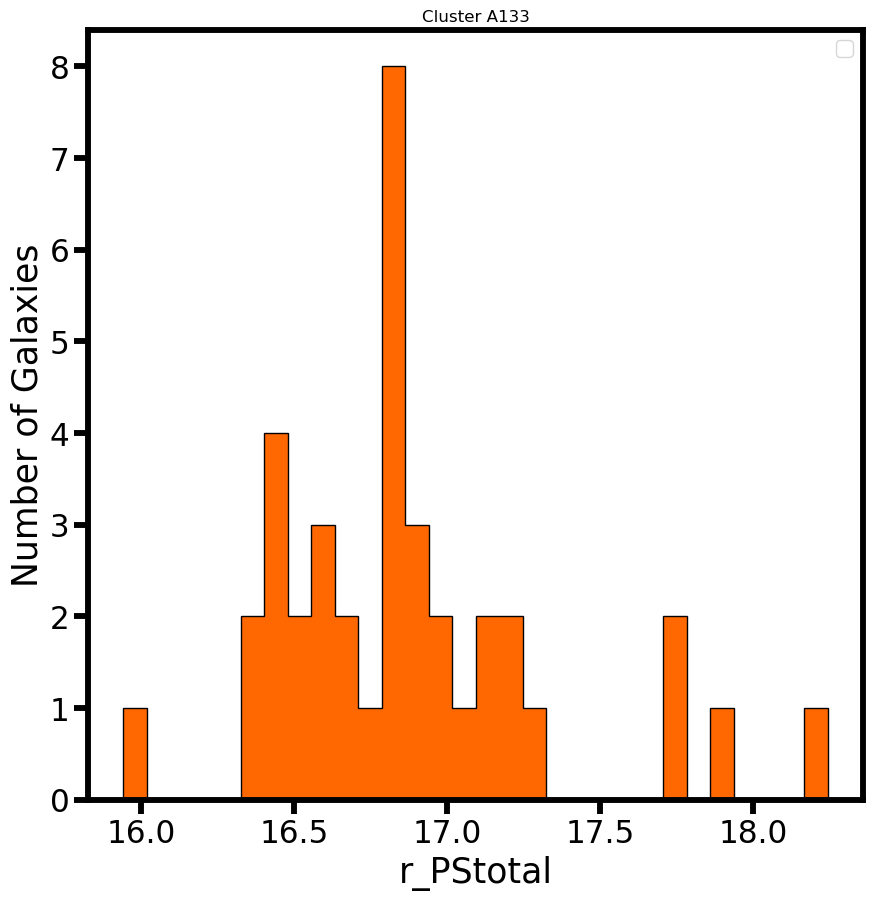

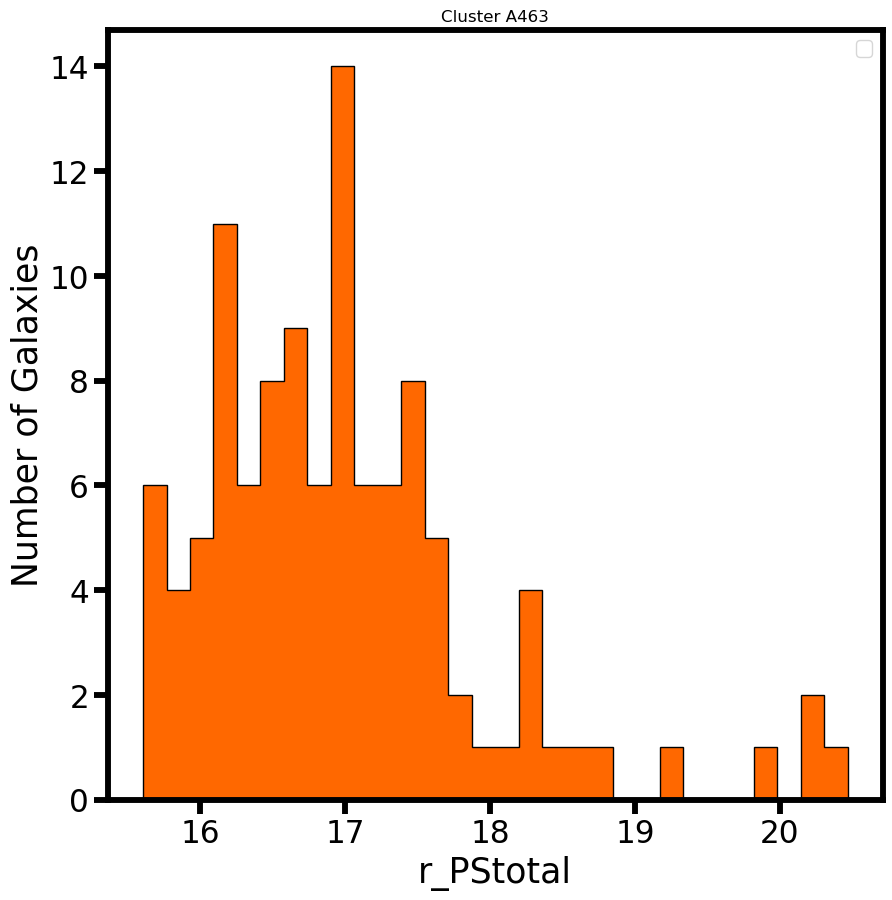

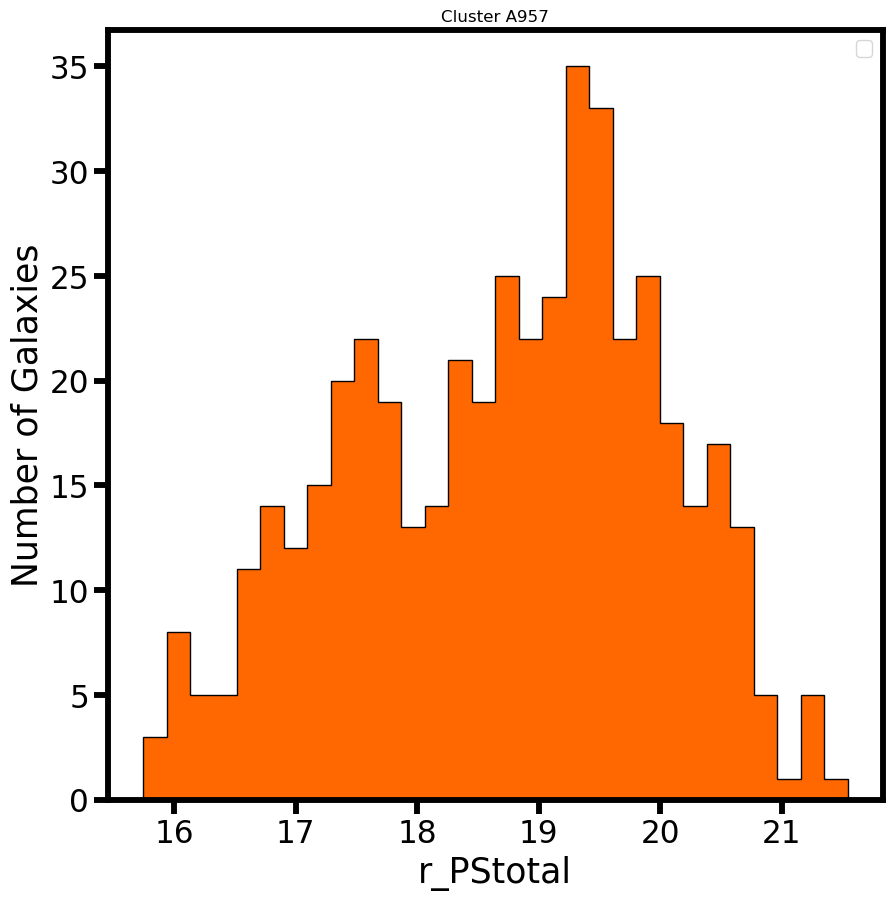

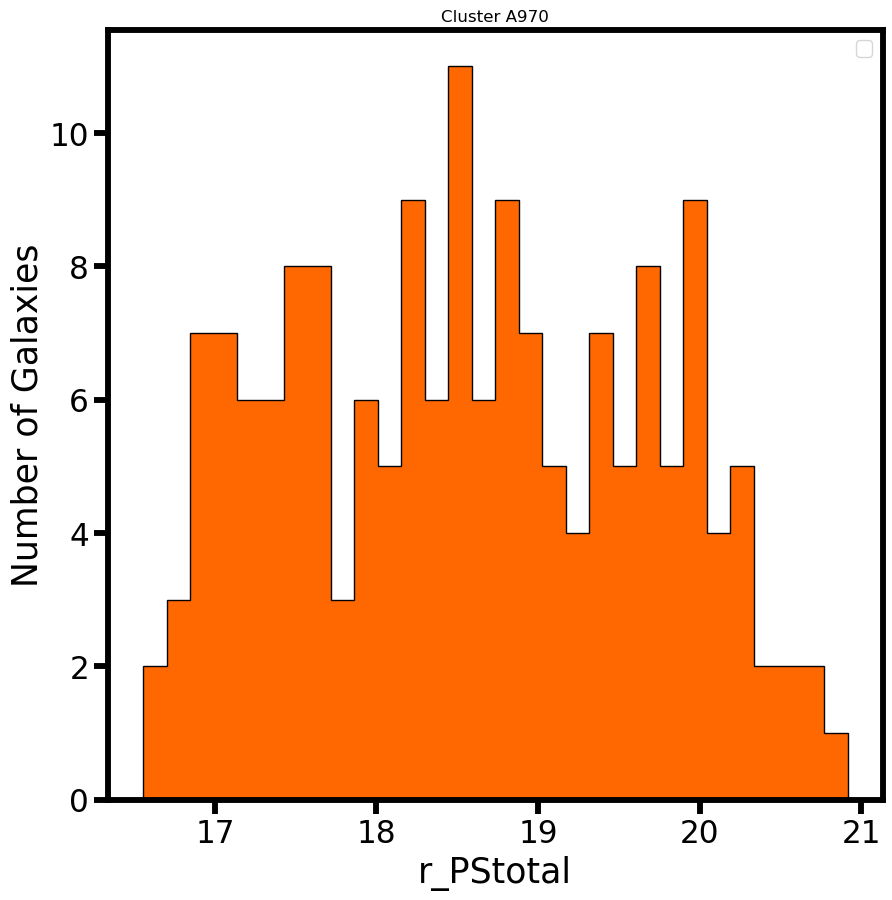

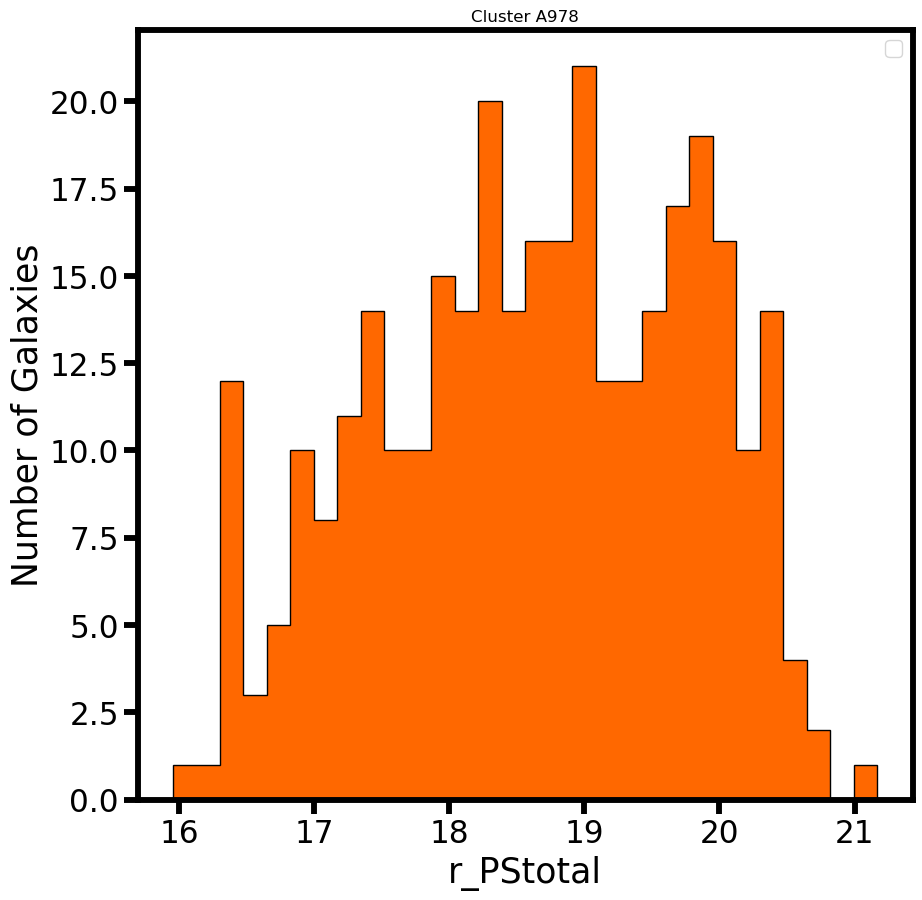

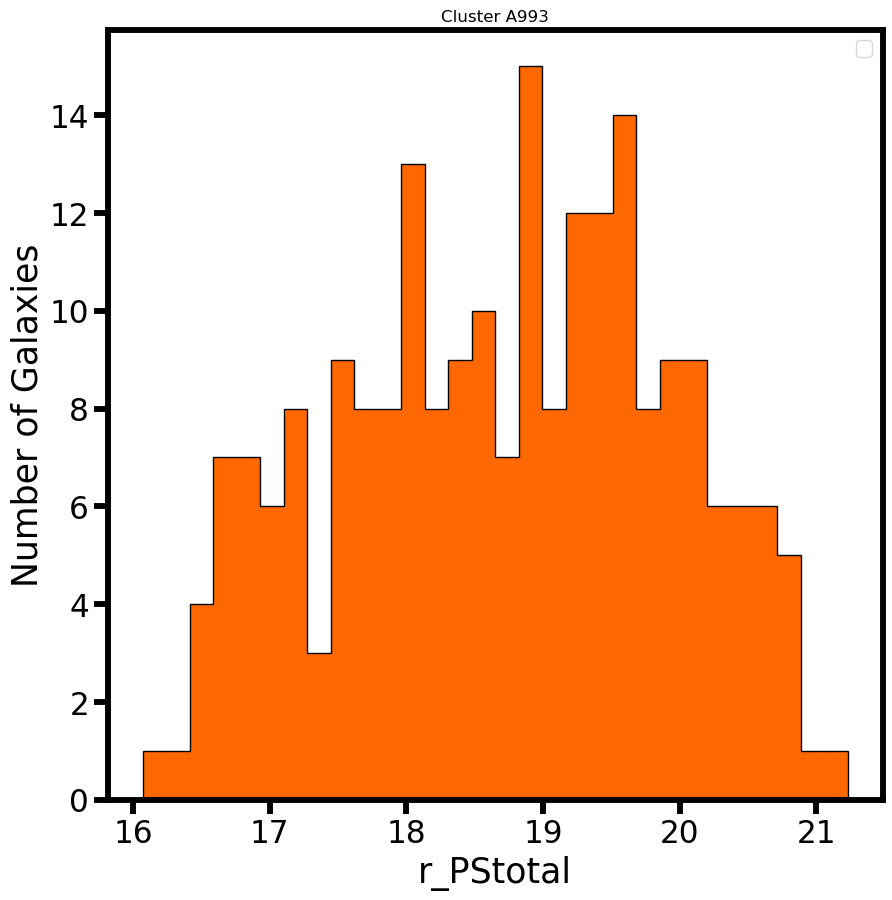

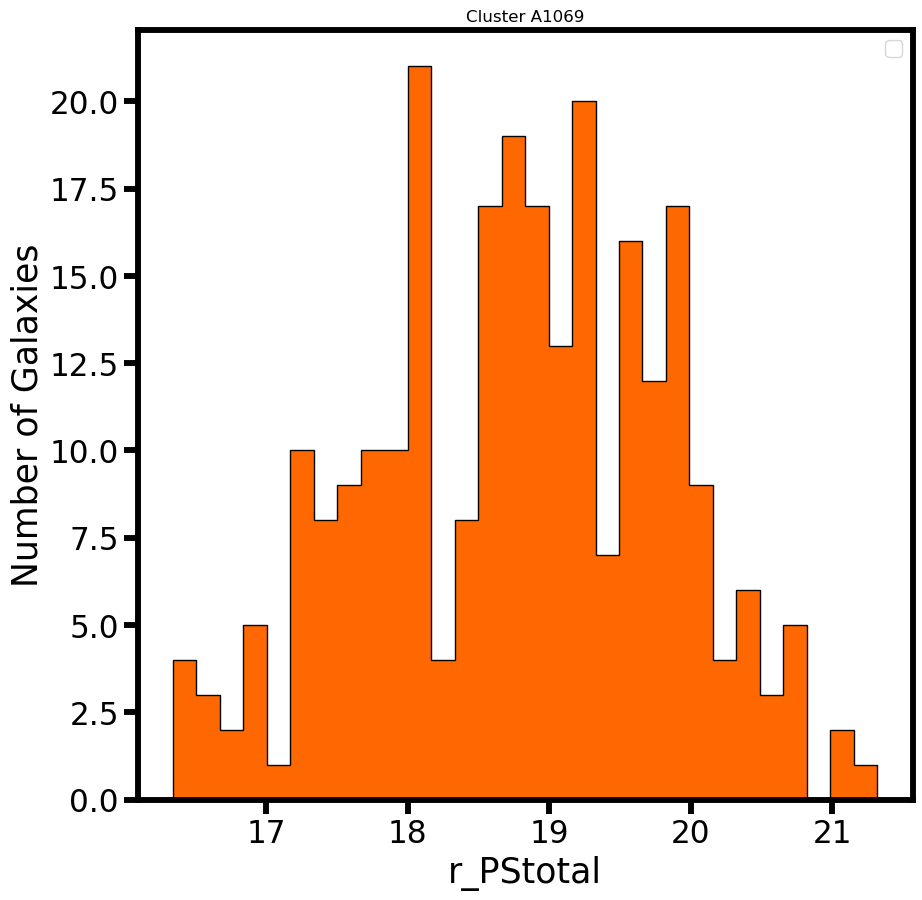

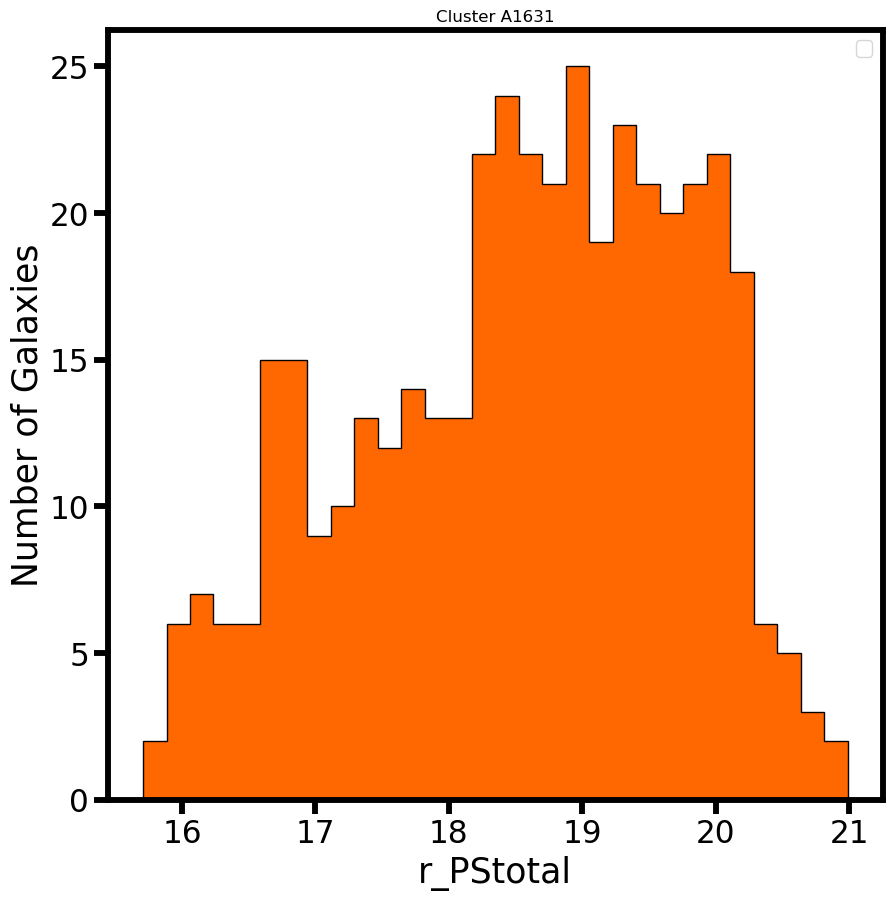

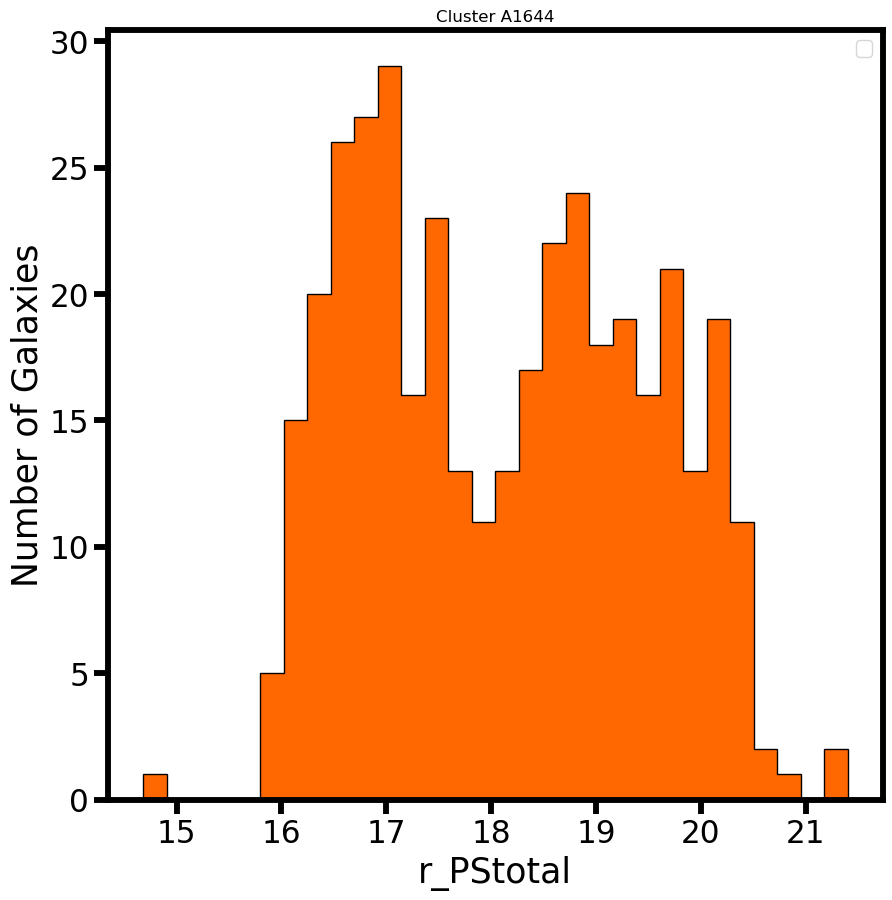

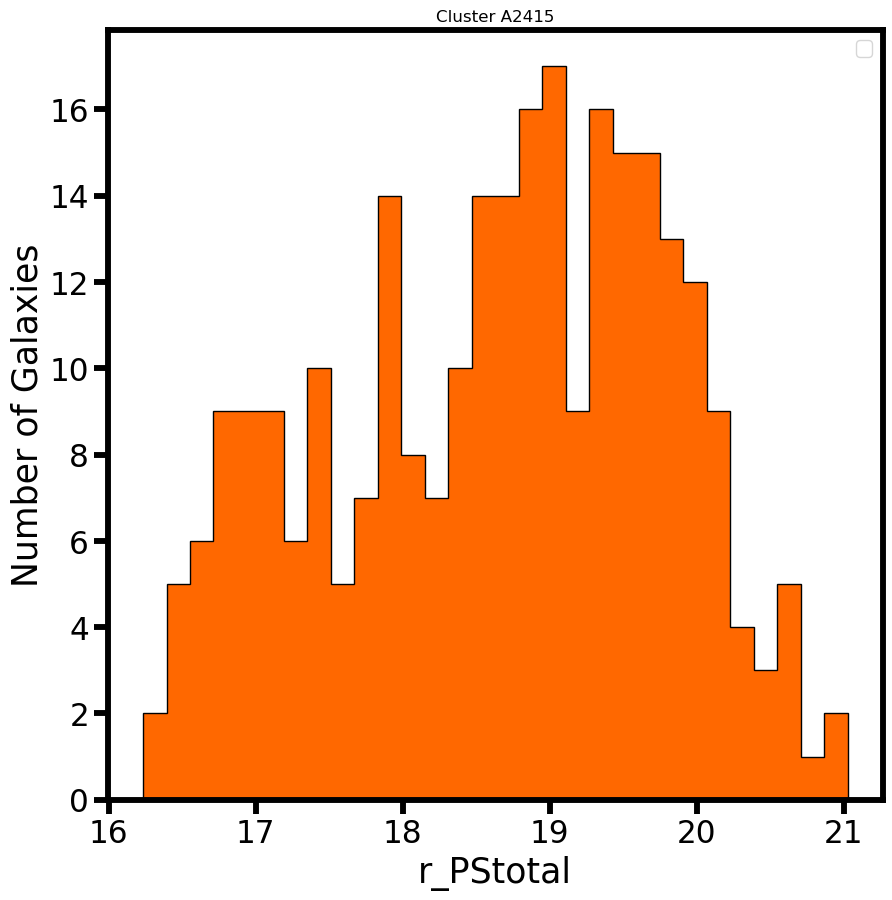

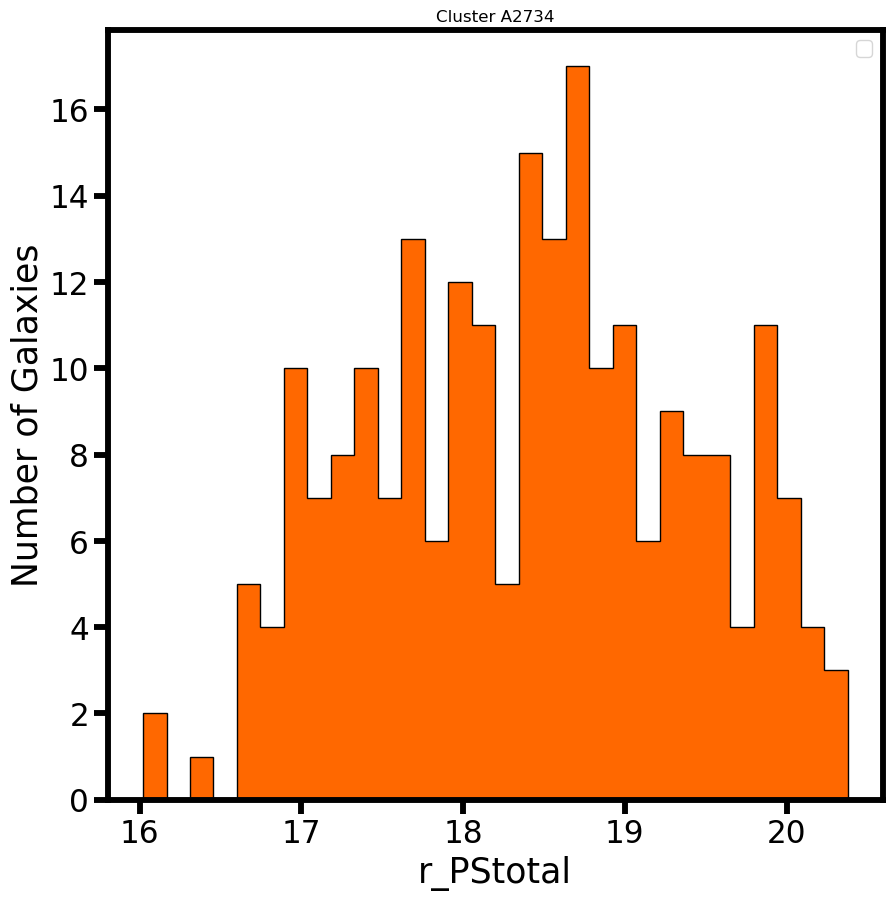

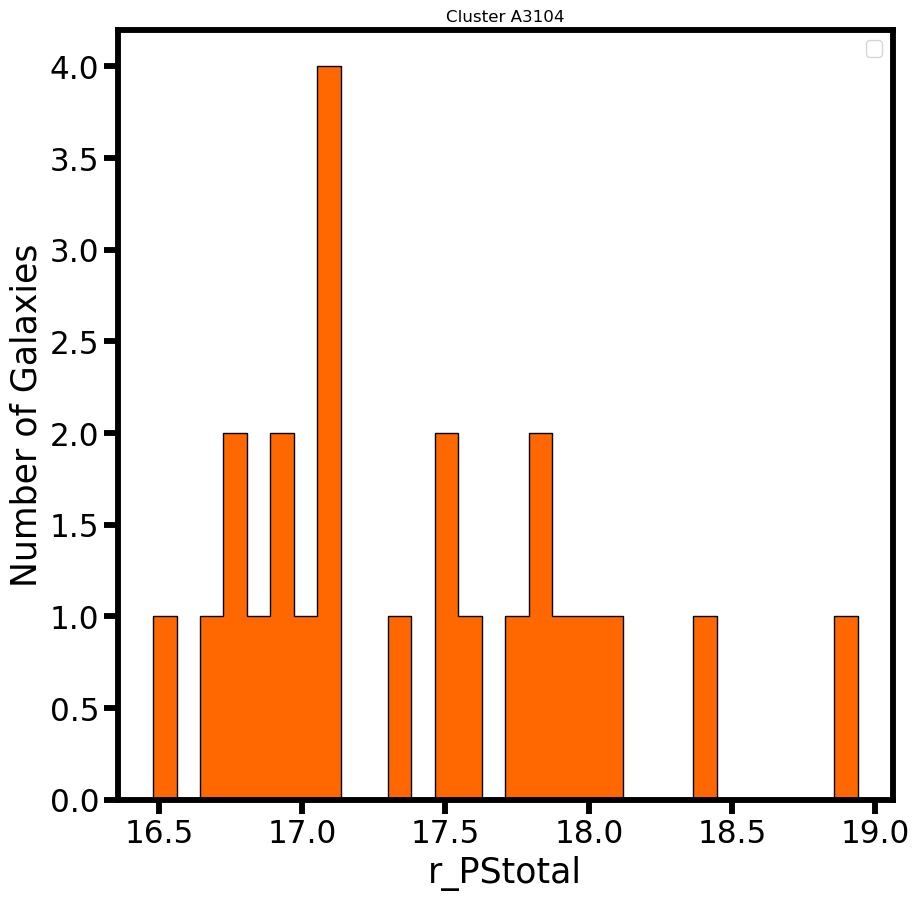

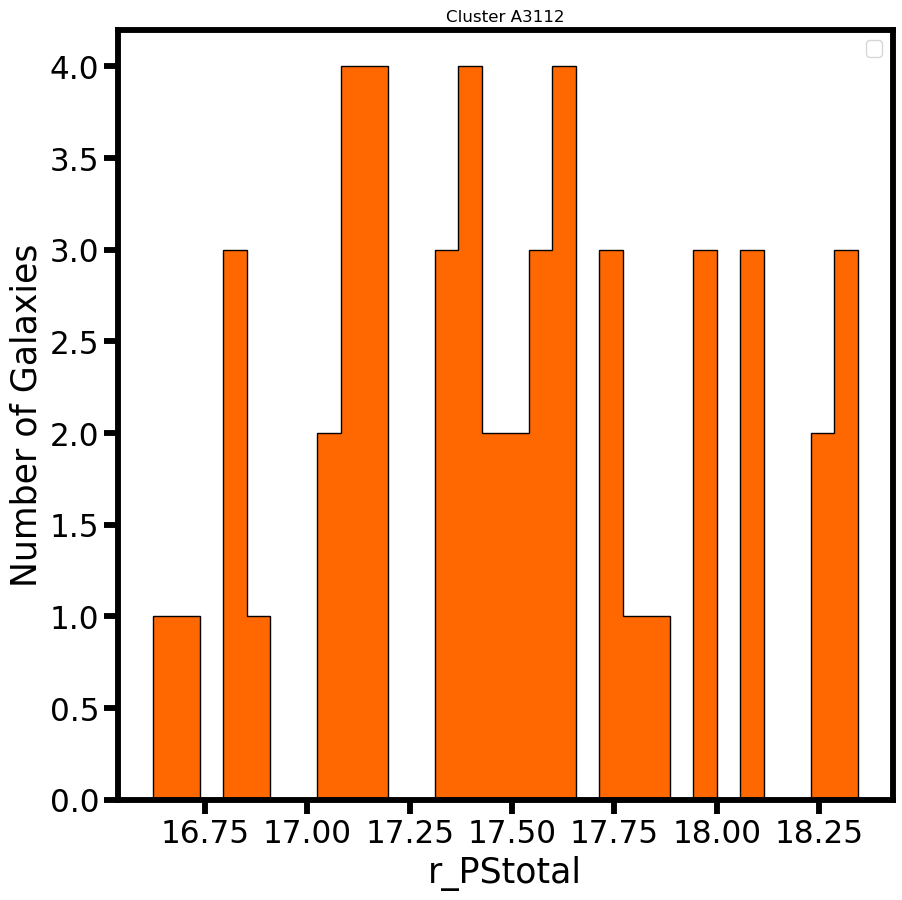

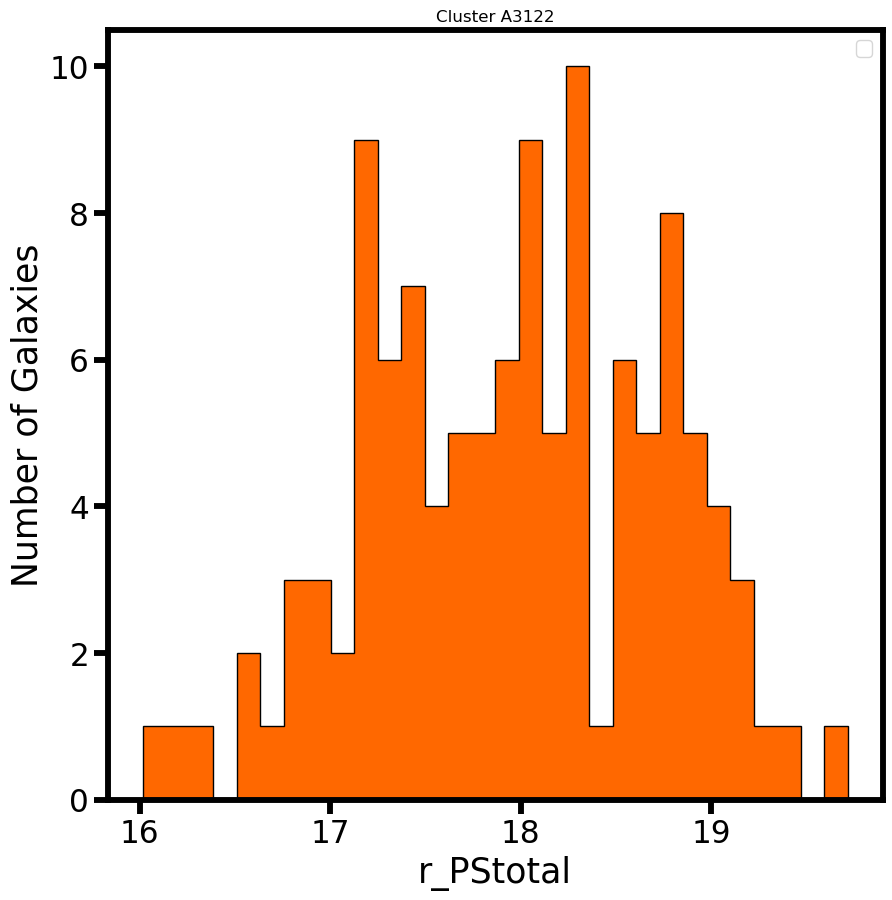

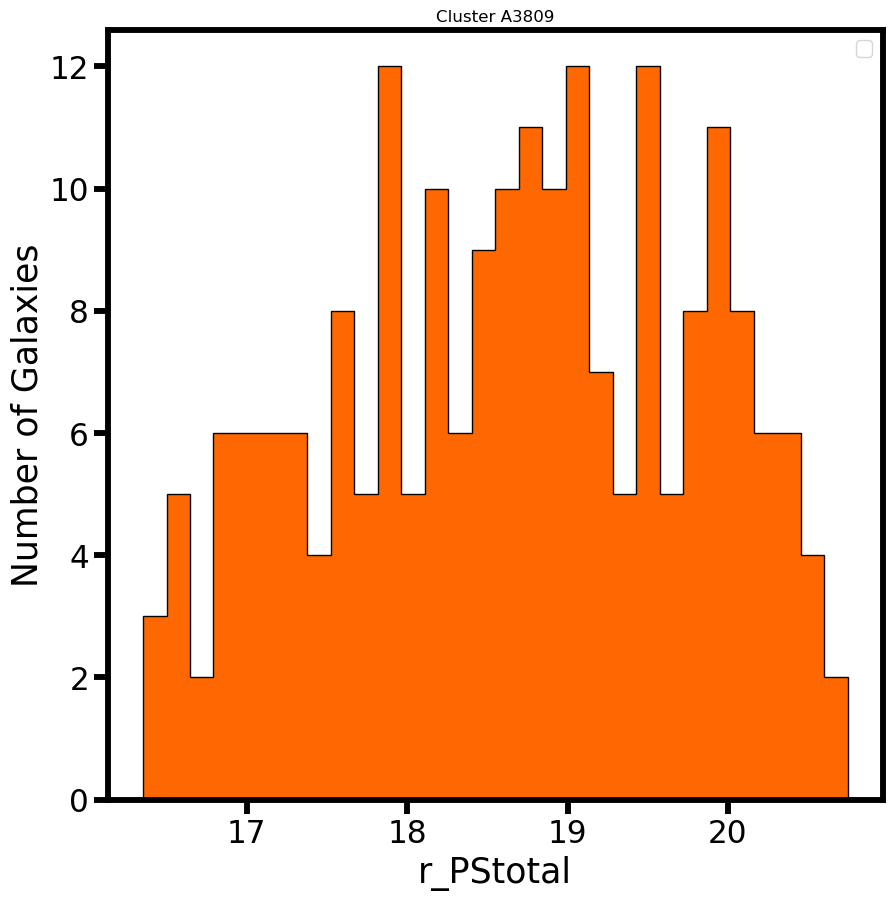

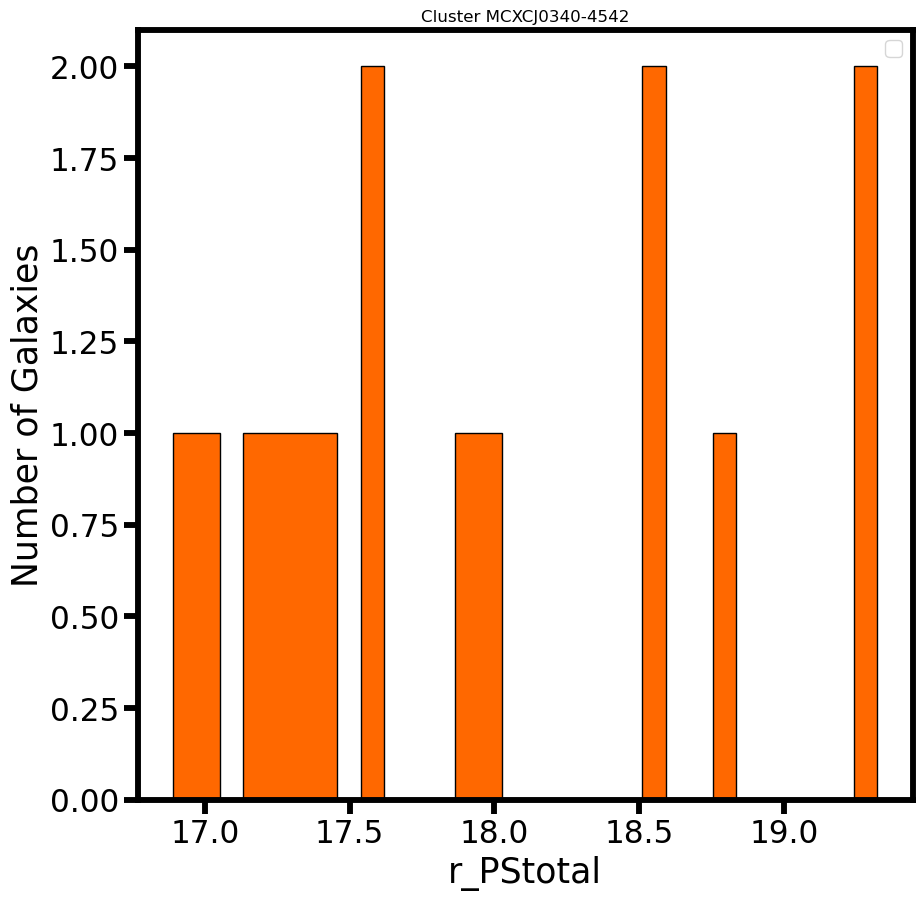

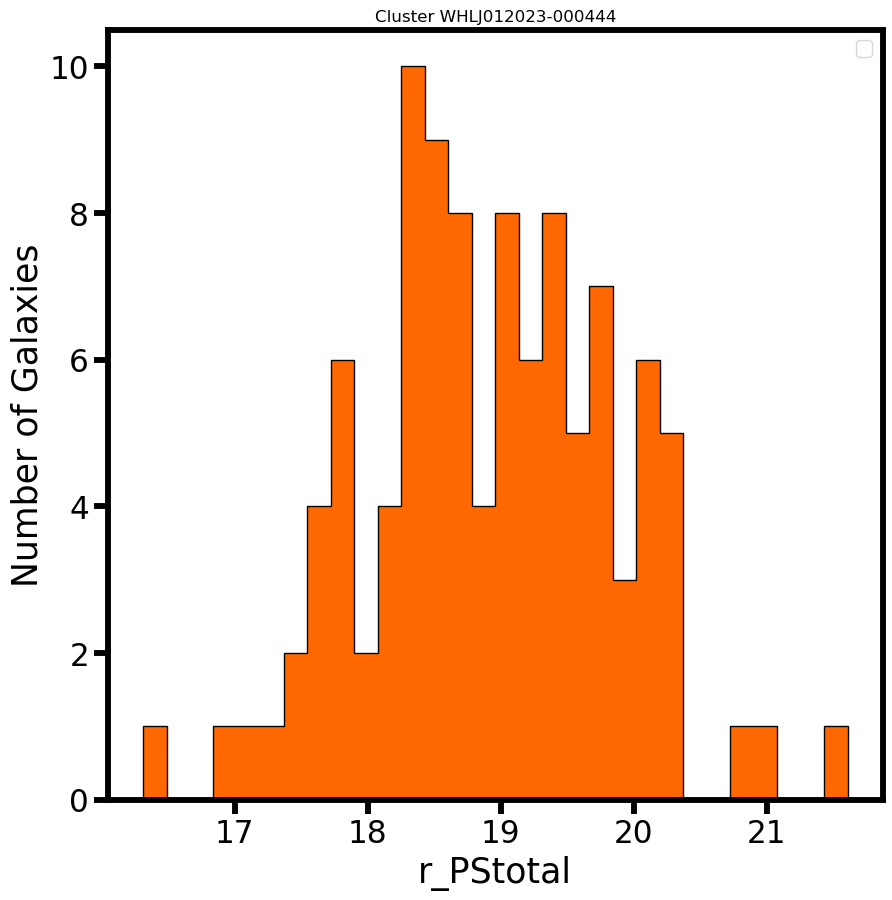

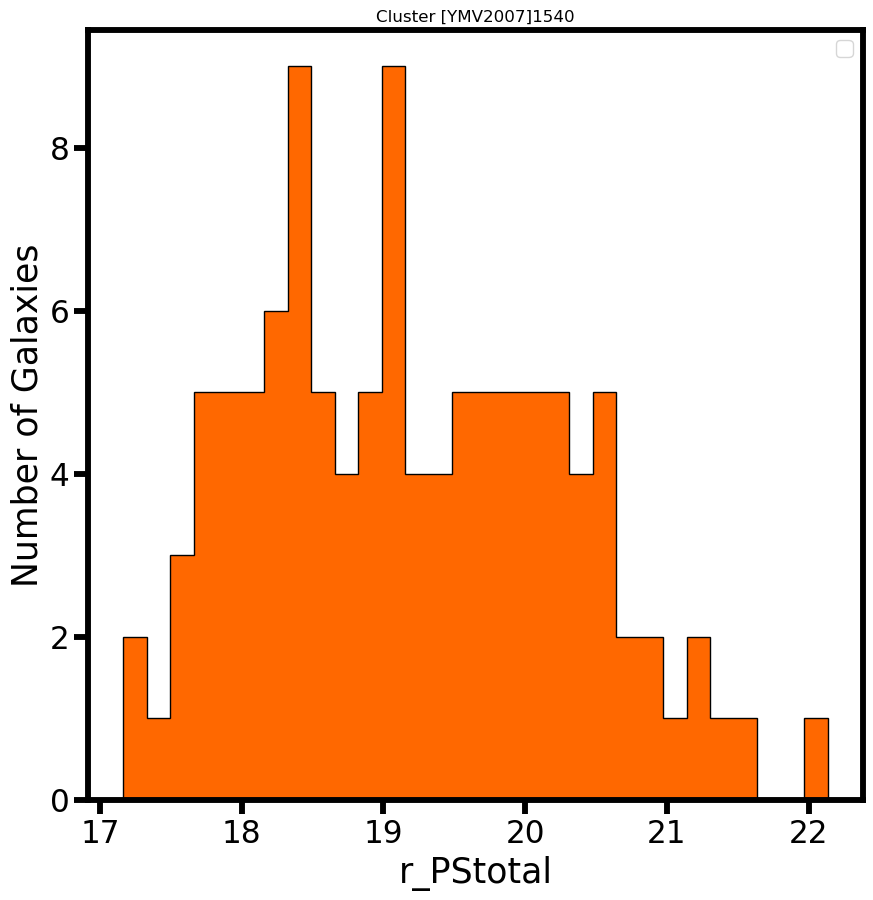

In [11]:
for i, cl_name in enumerate(cl_names):

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)

    t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
    # clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
    # zc = clusters_properties["z"][clusters_properties["Cluster"]==cl_name].values[0]

    r = t["r_PStotal"].values
    # phot_members = (t["flag_member_photz1"] == 0) & (t["r_PStotal"] < 21)
    spec_members = (t["flag_member"] == 0) & (t["R"] < 5)

    # ax.hist(r[phot_members], bins=30, color=colors1[3], histtype='stepfilled', edgecolor='k', alpha=0.5, range=(0.04, 0.15), label="Phot members")
    ax.hist(r[spec_members], bins=30, color=colors1[7], histtype='stepfilled', edgecolor='k', alpha=1.0)
    ax.set_title("Cluster {}".format(cl_name))
    ax.set_xlabel("r_PStotal", fontsize=25)
    ax.set_ylabel("Number of Galaxies", fontsize=25)
    ax.legend(fontsize=15)

    plt.savefig("../figures/SCALE/membership_05022026/r_magnitudes_{}".format(cl_name) ,dpi='figure', format='png')

/tmp/ipykernel_4335/3208950790.py:6: DtypeWarning: Columns (114,115,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
/tmp/ipykernel_4335/3208950790.py:6: DtypeWarning: Columns (139) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
/tmp/ipykernel_4335/3208950790.py:6: DtypeWarning: Columns (114,139) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))


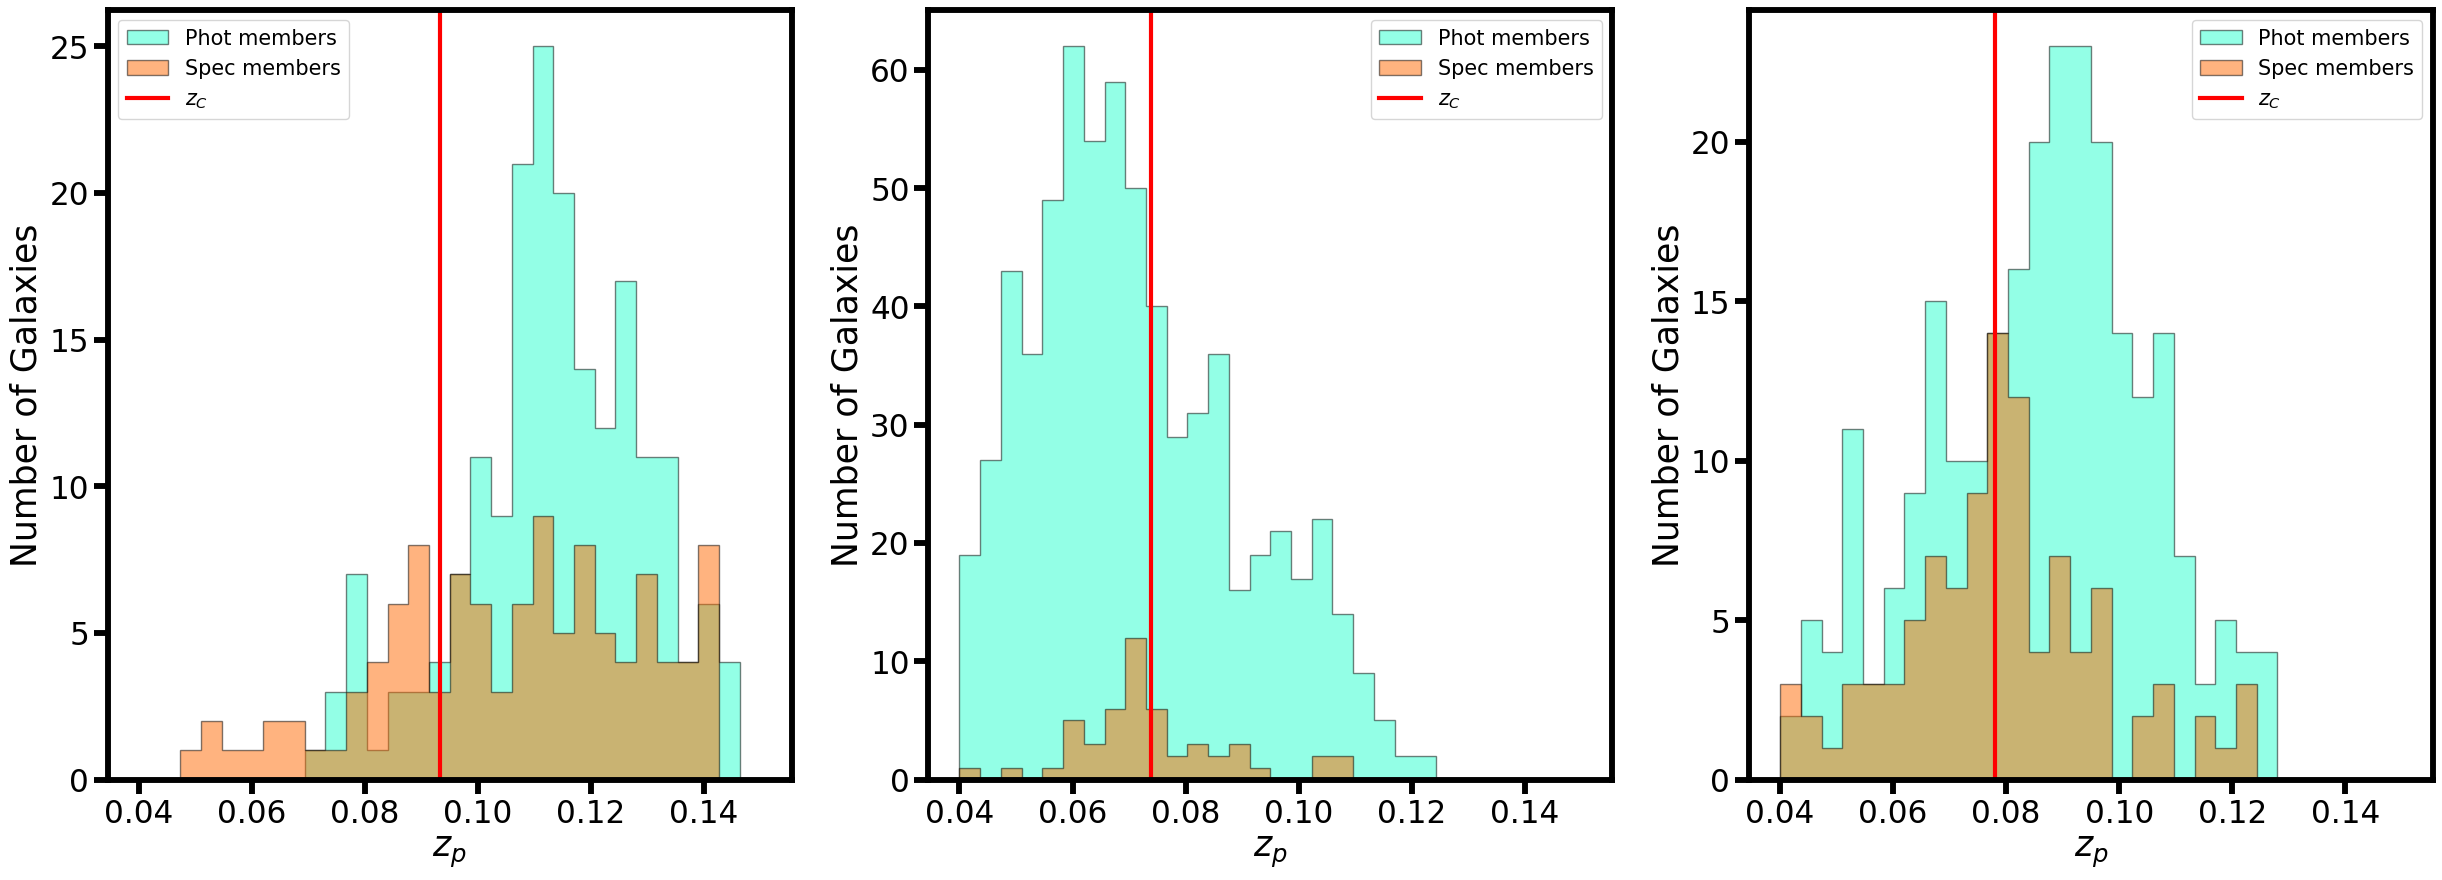

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(30, 10))

cl_names_test = ["[YMV2007]1540", "A3112", "WHLJ012023-000444"]
for i, cl_name in enumerate(cl_names_test):
    ax = axs[i]
    t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
    clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
    zc = clusters_properties["z"][clusters_properties["Cluster"]==cl_name].values[0]

    zp = t["zml"]
    phot_members = (t["flag_member_photz1"] == 0) & (t["r_PStotal"] < 21)
    spec_members = (t["flag_member"] == 0) & (t["R"] < 5)

    ax.hist(zp[phot_members], bins=30, color=colors1[3], histtype='stepfilled', edgecolor='k', alpha=0.5, range=(0.04, 0.15), label="Phot members")
    ax.hist(zp[spec_members], bins=30, color=colors1[7], histtype='stepfilled', edgecolor='k', alpha=0.5, range=(0.04, 0.15), label="Spec members")
    # ax.hist(zp[phot_members & spec_members], bins=30, color="green", histtype='stepfilled', edgecolor='k', alpha=0.5, range=(0.04, 0.15), label="Phot & Spec members")
    # ax.hist(zp[~phot_members & spec_members], bins=30, color="red", histtype='stepfilled', edgecolor='k', alpha=0.5, range=(0.04, 0.15), label="Spec / not phot members")
    ax.axvline(zc, color="red", lw=3, label=r"$z_C$")
    ax.set_xlabel(r"$z_p$", fontsize=25)
    ax.set_ylabel("Number of Galaxies", fontsize=25)
    ax.legend(fontsize=15)

In [ ]:
#==================================================================
#TESTE QUE EU FIZ PRA CLAUDIA, COMPARANDO O MEU MÉTODO COM O DELA E USANDO VÁRIOS LIMITES DE MAGNITUDE
#==================================================================

#Deletar aqueles que tão ruins
clusters_indexes = np.delete(range(0, 84, 1), [3, 5, 22, 30, 40, 45, 79, 44, 36, 41, 43, 47, 49, 50, 59, 62, 65, 69, 83])
clusters_names = np.array([clusters_properties["Cluster"][cl] for cl in clusters_indexes])


#Create the dataframes to store the metrics for each cluster, r_cut and method
metrics_my_method = pd.DataFrame()
metrics_method_claudia = pd.DataFrame()
metrics_my_method["Cluster"] = clusters_names
metrics_method_claudia["Cluster"] = clusters_names

f = 1.5
fr = 5
#Vamos testar como ficam as taxas de recuperação cortando em diferentes valores de magnitude.
for r_cut in [21, 20, 19, 18, 17, 16]:

    recov_rate_my_method_list = []
    recov_rate_method_claudia_list = []

    for cl in clusters_indexes:

        print("Running for cluster:", cl)

        cl_name = clusters_properties["Cluster"][cl]
        print(cl_name)

        # cl_name = 'A1644'
        # cl = np.argwhere(clusters_properties["Cluster"]==cl_name)[0][0]

        t = pd.read_csv("tables/SCALE/clusters_v7_csv/"+cl_name+".csv")

        #PROPERTIES OF GALAXIES
        r_PStotal = t["r_PStotal"].values
        mask_good = ~np.isnan(r_PStotal) & (r_PStotal < r_cut)
        t_good = t[mask_good]

        ras = t_good["ra"].values
        decs = t_good["dec"].values
        zphot = t_good["zml"].values
        z = t_good["z"].values
        r_PStotal = t_good["r_PStotal"].values
        odds = t_good["odds"].values

        pdf_weights = np.array([t_good[col_name] for col_name in ["pdf_weights_" + str(i) for i in range(0, 3)]])
        pdf_means = np.array([t_good[col_name] for col_name in ["pdf_means_" + str(i) for i in range(0, 3)]])
        pdf_stds = np.array([t_good[col_name] for col_name in ["pdf_stds_" + str(i) for i in range(0, 3)]])

        members = t_good["flag_member"] == 0

        #PROPERTIES OF THE CLUSTER
        ra0 = clusters_properties["R.A."][cl]
        dec0 = clusters_properties["Dec."][cl]
        z_cluster = clusters_properties["z"][cl]
        r200_mpc = clusters_properties["R200"][cl]
        # zp_bias = float(clusters_properties["off"][cl])

        kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
        r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

        print("Cluster redshift: ", z_cluster)

        sigma_z = np.array([sigma_nmad_(r) for r in r_PStotal])

        dist = clustercentric_distance(ras, decs, ra0, dec0)
        mask_cluster_region = (dist < fr*r200_deg)

        mask_cluster = mask_cluster_region & (zphot > z_cluster - f*sigma_z*(1+z_cluster)) & (zphot < z_cluster + f*sigma_z*(1+z_cluster))


        #Compute photo-z bias and remove it from the photo-zs, redefining the mask_cluster
        z_bins = 20
        bw = (zphot[mask_cluster].max() - zphot[mask_cluster].min()) / z_bins

        kde = KernelDensity(kernel="gaussian", bandwidth=bw).fit(zphot[mask_cluster][:, np.newaxis])
        zz_phot = np.linspace(zphot[mask_cluster].min(), zphot[mask_cluster].max(), len(zphot[mask_cluster]))[:, np.newaxis]
        log_dens_zz_phot = kde.score_samples(zz_phot)

        zp_peak = zz_phot[np.argmax(np.exp(log_dens_zz_phot))]
        zp_bias_mine = zp_peak - z_cluster

        zphot_unbiased = zphot - zp_bias_mine

        mask_cluster_unbiased =  (zphot_unbiased[mask_cluster_region] > z_cluster - f*sigma_z[mask_cluster_region]*(1+z_cluster)) & (
                                zphot_unbiased[mask_cluster_region] < z_cluster + f*sigma_z[mask_cluster_region]*(1+z_cluster))

        print("zp_bias = {}".format(zp_bias_mine))
        # print("zp_bias from Paulo= {}".format(zp_bias))


        Pmem = P_pz_v2(z_cluster, 
                    sigma_z[mask_cluster_region],
                    pdf_means.T[mask_cluster_region], 
                    pdf_weights.T[mask_cluster_region], 
                    pdf_stds.T[mask_cluster_region], 
                    fz=f)
        
        phot_members_mask = mask_cluster_unbiased & (Pmem > 0.5)


        #Members according to the method proposed by Claudia
        phot_members_claudia_mask = (zphot_unbiased[mask_cluster_region] > z_cluster - 0.01) & (
                                zphot_unbiased[mask_cluster_region] < z_cluster + 0.01) & (odds[mask_cluster_region] > 0.7)


        #Computing recovery rates and saving on the dataframes
        recov_rate_my_method = np.sum(members[mask_cluster_region] & phot_members_mask) / np.sum(members[mask_cluster_region])
        recov_rate_method_claudia = np.sum(members[mask_cluster_region] & phot_members_claudia_mask) / np.sum(members[mask_cluster_region])

        recov_rate_my_method_list.append(recov_rate_my_method)
        recov_rate_method_claudia_list.append(recov_rate_method_claudia)

    metrics_my_method["r < {}".format(r_cut)] = recov_rate_my_method_list
    metrics_method_claudia["r < {}".format(r_cut)] = recov_rate_method_claudia_list

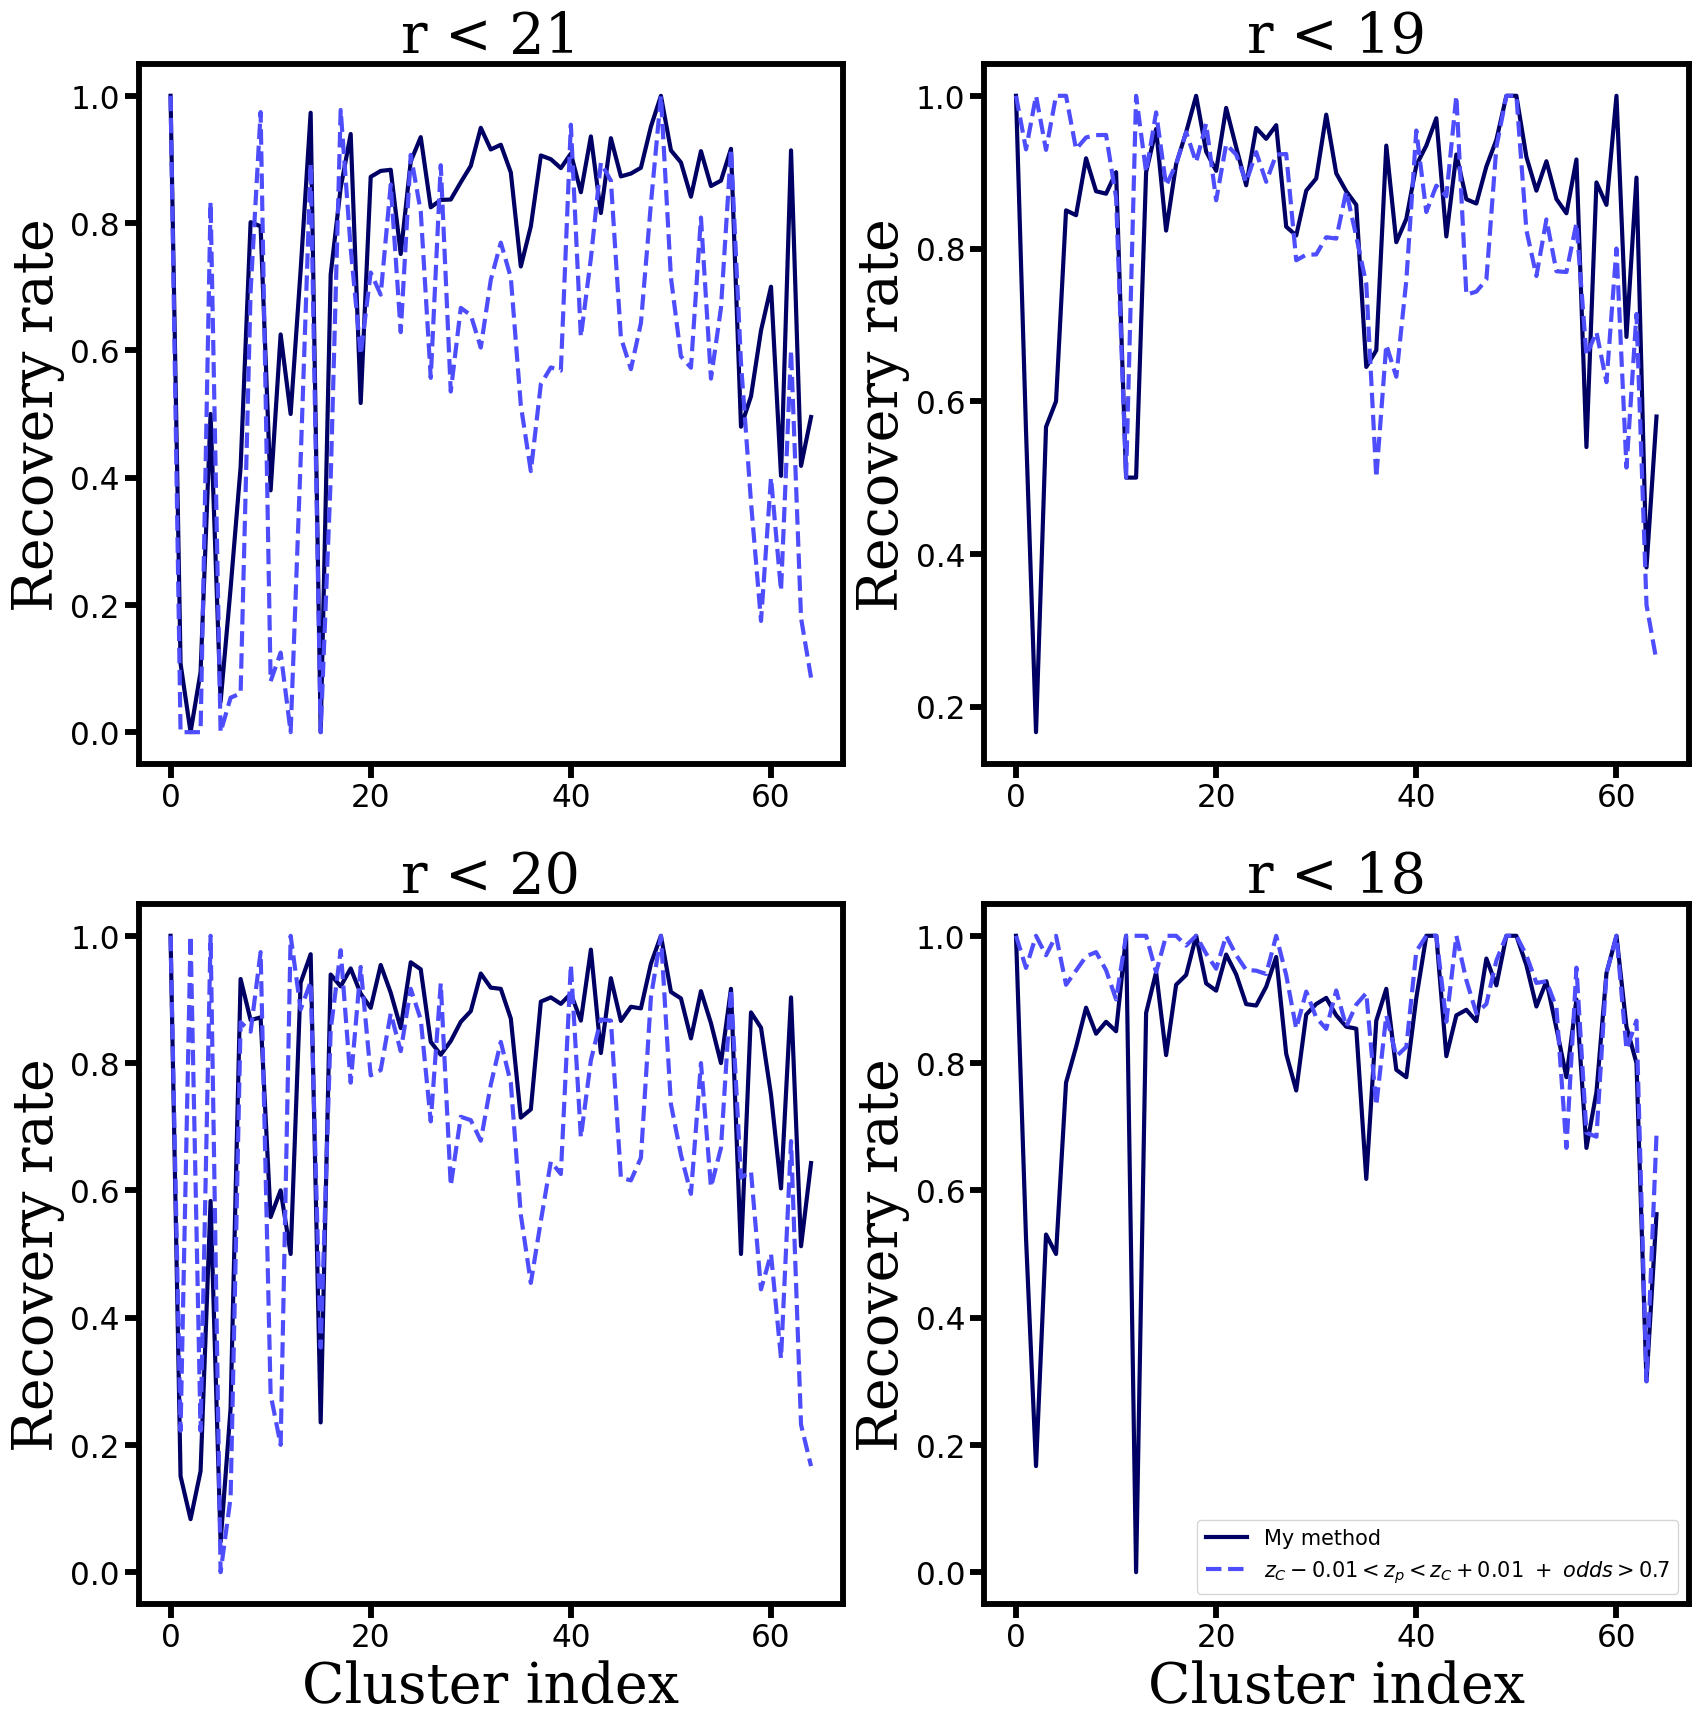

In [99]:
fig, axs = plt.subplots(2, 2, figsize=(20, 20))

for i, r_cut in enumerate([21, 20, 19, 18]):

    axs[i%2, i//2].plot(np.arange(65), metrics_my_method["r < {}".format(r_cut)], ls="solid", lw=3, color=colors3[0], label="My method")
    axs[i%2, i//2].plot(np.arange(65), metrics_method_claudia["r < {}".format(r_cut)], ls="dashed", lw=3, color=colors2[0], 
                                    label=r"$z_C - 0.01 < z_p < z_C + 0.01\ +\ odds > 0.7$")
    axs[i%2, i//2].set_ylabel("Recovery rate", fontdict=font)
    axs[i%2, i//2].set_title("r < {}".format(r_cut), fontdict=font)
        
axs[1, 0].set_xlabel("Cluster index", fontdict=font)
axs[1, 1].set_xlabel("Cluster index", fontdict=font)
axs[i%2, i//2].legend(fontsize=15)

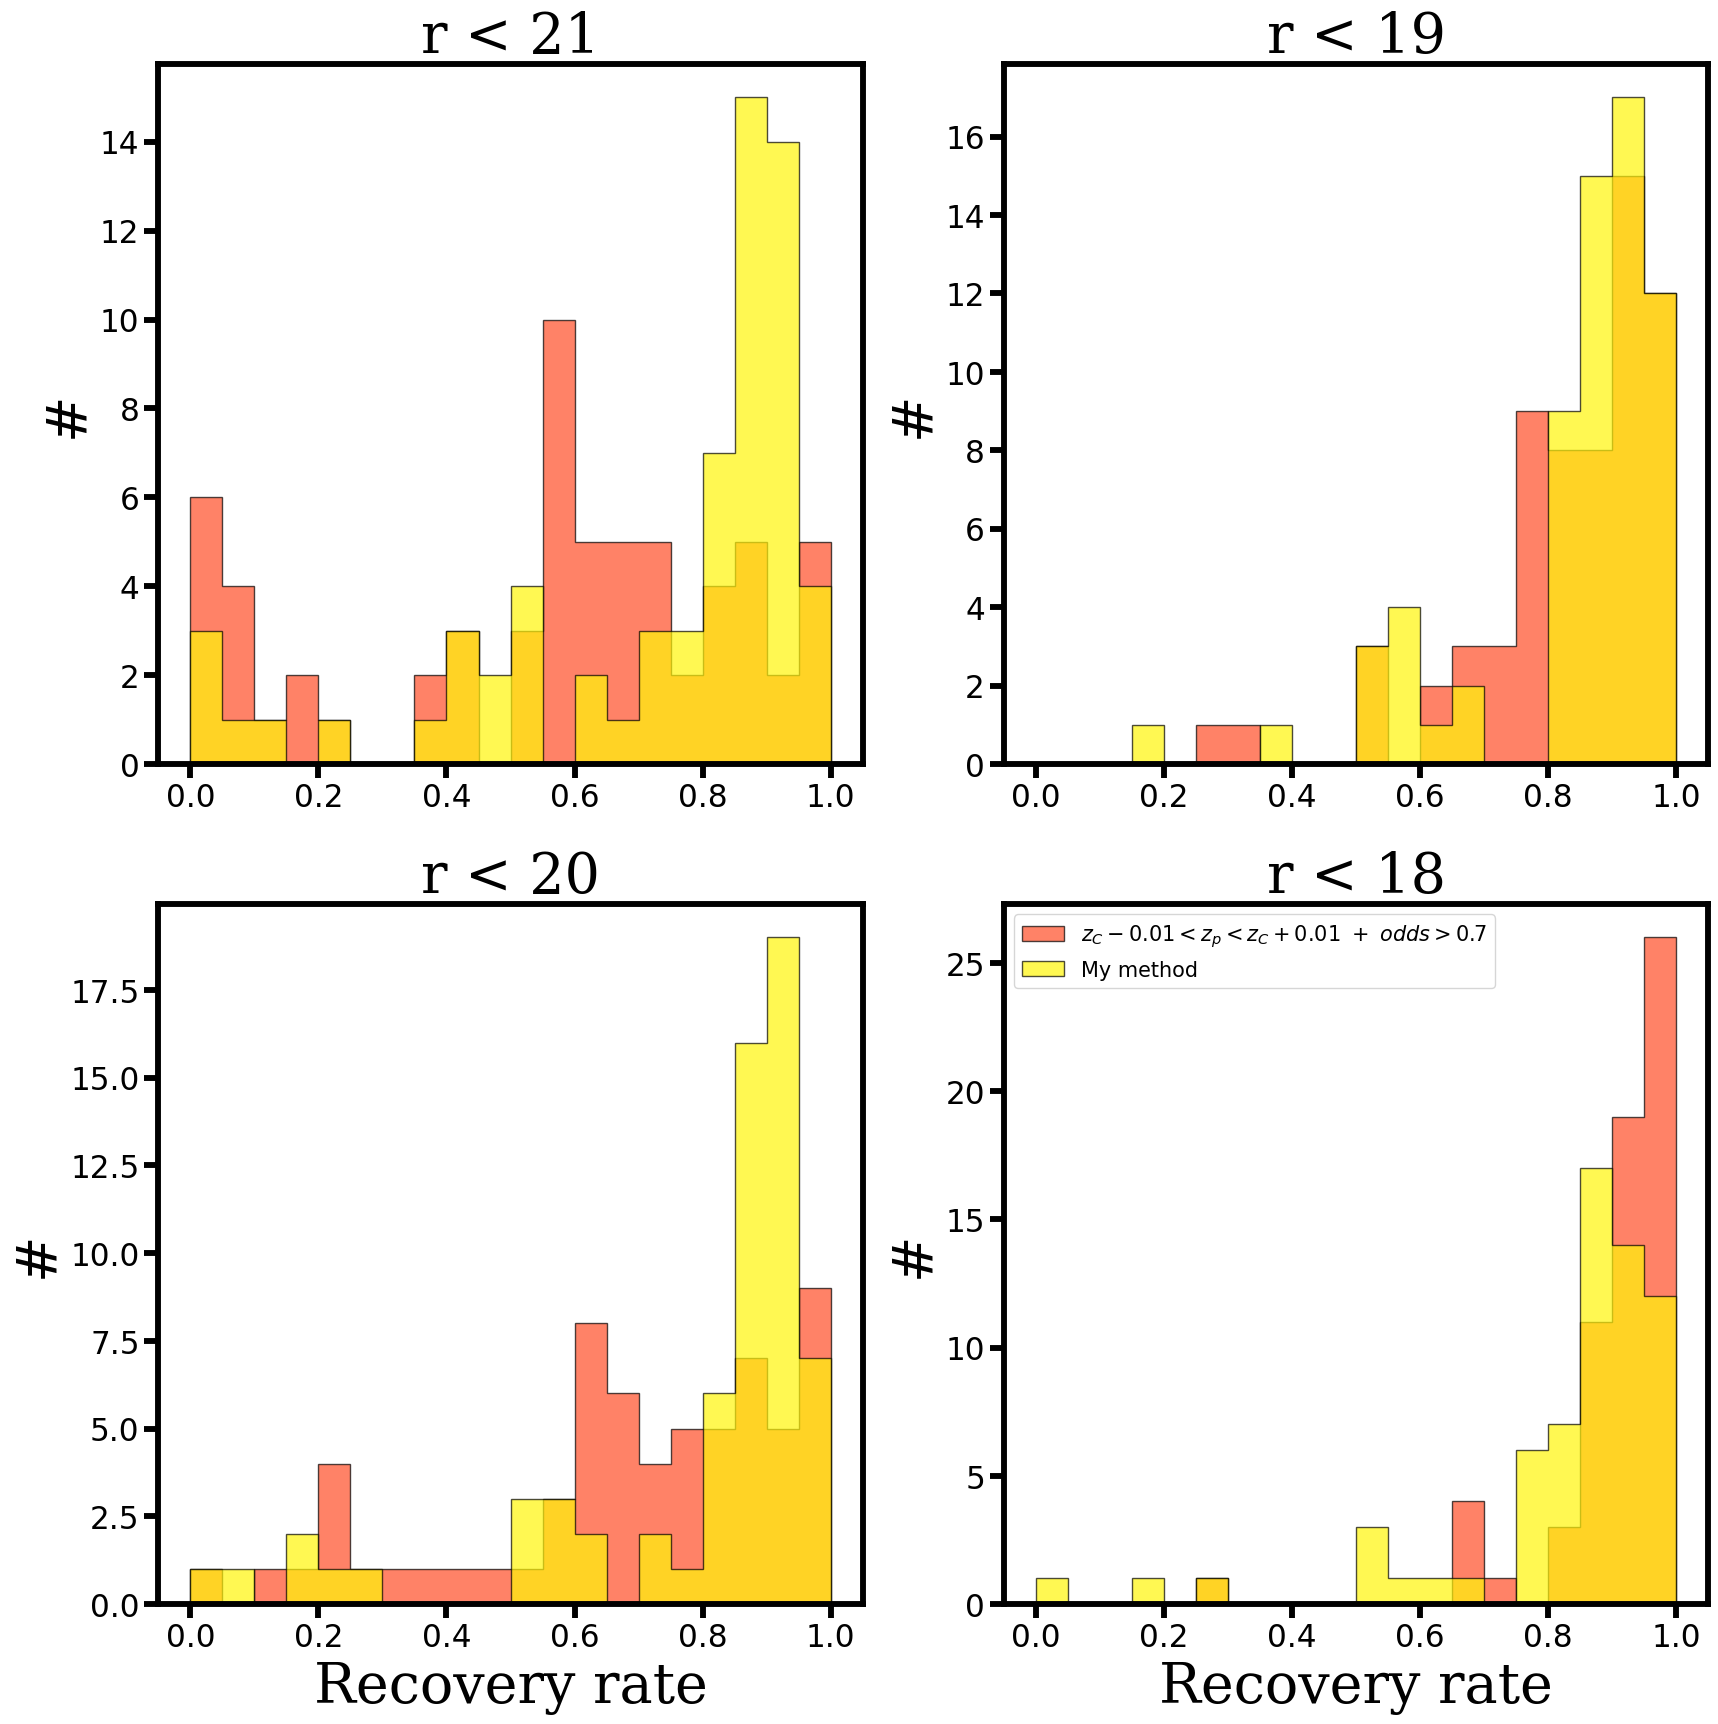

In [97]:
fig, axs = plt.subplots(2, 2, figsize=(20, 20))

for i, r_cut in enumerate([21, 20, 19, 18]):

    axs[i%2, i//2].hist(metrics_method_claudia["r < {}".format(r_cut)], bins=20, color=colors2[8], range=[0, 1], histtype="stepfilled", edgecolor="k",
                                    alpha=0.7, label=r"$z_C - 0.01 < z_p < z_C + 0.01\ +\ odds > 0.7$")
    axs[i%2, i//2].hist(metrics_my_method["r < {}".format(r_cut)], bins=20, color=colors3[8], histtype="stepfilled", range=[0, 1], edgecolor="k", 
                                    alpha=0.7, label="My method")
    axs[i%2, i//2].set_ylabel("#", fontdict=font)
    axs[i%2, i//2].set_title("r < {}".format(r_cut), fontdict=font)
        
axs[1, 0].set_xlabel("Recovery rate", fontdict=font)
axs[1, 1].set_xlabel("Recovery rate", fontdict=font)
axs[i%2, i//2].legend(fontsize=15)

### Re-analyzing A168 and MKW4 for the paper

/tmp/ipykernel_3507221/2544773967.py:1: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format("MKW4"))


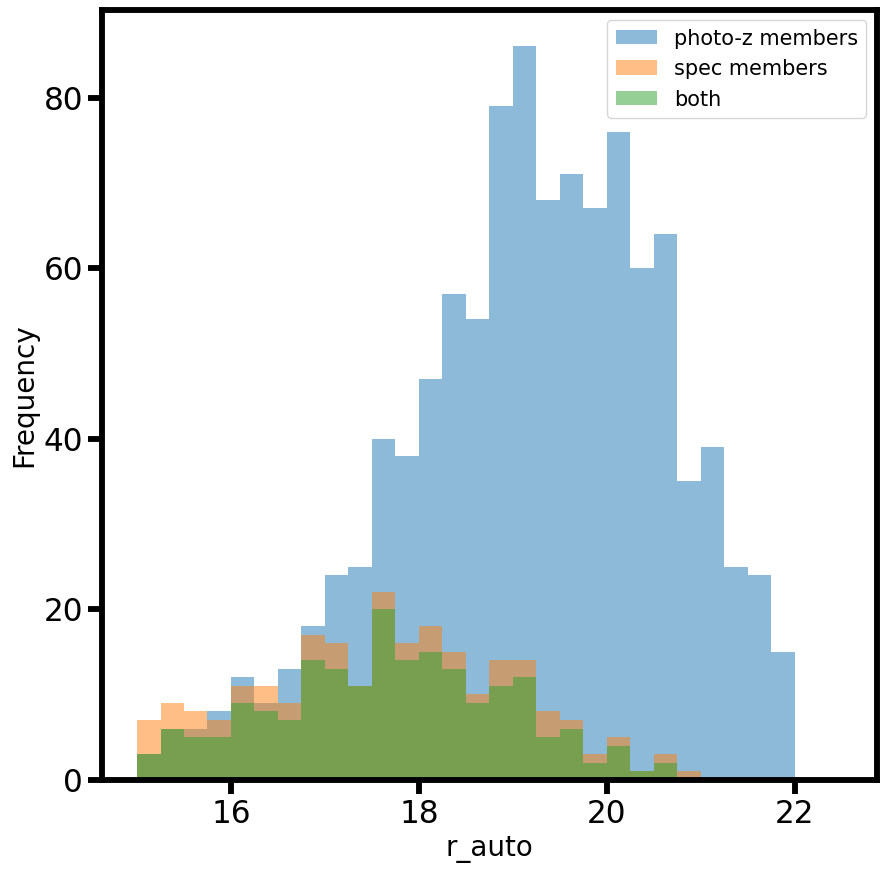

In [26]:
t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format("MKW4"))

spec_members = t["flag_member"].values == 0
phot_members = t["flag_member_photz1"].values == 0

plt.figure(figsize=(10, 10))
plt.xlabel("r_auto", fontsize=20)
plt.ylabel("Frequency", fontsize=20)
plt.hist(t["r_auto"].values[phot_members],bins=30, alpha=0.5, label="photo-z members", range=[15.0, 22.5])[2]
plt.hist(t["r_auto"].values[spec_members & (t["R"].values<5)],bins=30, alpha=0.5, label="spec members", range=[15.0, 22.5])[2]
plt.hist(t["r_auto"].values[spec_members & (t["R"].values<5) & phot_members],bins=30, alpha=0.5, label="both", range=[15.0, 22.5])[2]
plt.legend(fontsize=15)
# plt.show()


In [ ]:
#Cosmologia usada no SCALE:
#H0 = 70 km/Mpc/s
#Omega_M = 0.3

#Recalcular os r200 pra poder dar os mesmos valores que a Claudia.

In [ ]:
cluster = "MKW4"

t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
r_auto = t["r_auto"].values
mask_good = ~np.isnan(r_auto) & (t["radius_deg"].values < 3.834) 
t_good = t[mask_good]
spec_members = t_good["flag_member"].values == 0

phot_spec_members = (t_good["flag_member_photz1"].values == 0) & (t_good["flag_member"].values == 0)
print(np.sum(phot_spec_members))



202


/tmp/ipykernel_664056/2269657908.py:3: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))


In [22]:
cluster = "MKW4"

t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
r_auto = t["r_auto"].values
mask_good = ~np.isnan(r_auto) & (t["R"].values < 5) 
t_good = t[mask_good]
spec_members = t_good["flag_member"].values == 0

print(np.sum(spec_members))

phot_spec_members = (t_good["flag_member_photz1"].values == 0) & (t_good["flag_member"].values == 0)
print(np.sum(phot_spec_members))

285
202


/tmp/ipykernel_664056/3746912191.py:3: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))


In [ ]:
#Número de membros fotométricos sem z. 

mask = np.isnan(t_good["z"]) & (t_good["flag_member_photz1"].values == 0) & (t_good["r_auto"].values < 20.5)

np.sum(mask)

np.int64(257)

In [30]:
for cluster in ["A168", "MKW4"]:
    r_cut = 20.5
    odds_cut = 0.5

    t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
    # r_PStotal = t["r_PStotal"].values
    # mask_good = ~np.isnan(r_PStotal) & (r_PStotal <= r_cut)

    r_auto = t["r_auto"].values
    mask_good = ~np.isnan(r_auto) & (r_auto <= r_cut) & (t["odds"].values >= odds_cut)
    t_good = t[mask_good]

    spec_members = t_good["flag_member"].values == 0
    phot_members = t_good["flag_member_photz1"].values == 0

    recovery_rate = np.sum(spec_members & (t_good["R"].values < 5) & phot_members) / np.sum(spec_members & (t_good["R"].values < 5))
    print("Recovery rate for cluster {}: {:.2f}%".format(cluster, recovery_rate*100))

    new_phot_members = np.sum(phot_members) - np.sum(spec_members & phot_members)
    print("Number of new photometric members for cluster {}: {}".format(cluster, new_phot_members))
    print("Number of spec members inside 5R200 for cluster {}: {}".format(cluster, np.sum(spec_members & (t_good["R"].values < 5))))

    print()

Recovery rate for cluster A168: 90.18%
Number of new photometric members for cluster A168: 552
Number of spec members inside 5R200 for cluster A168: 336

Recovery rate for cluster MKW4: 75.00%
Number of new photometric members for cluster MKW4: 495
Number of spec members inside 5R200 for cluster MKW4: 252



/tmp/ipykernel_3507221/2994095862.py:5: DtypeWarning: Columns (97,114,115,139) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
/tmp/ipykernel_3507221/2994095862.py:5: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))


/tmp/ipykernel_3507221/2556419031.py:5: DtypeWarning: Columns (97,114,115,139) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
/home/elismar/miniconda3/envs/Doc/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3577: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will stop working in a future release. Pass it positionally to suppress this warning.
  exec(code_obj, self.user_global_ns, self.user_ns)
/tmp/ipykernel_3507221/2556419031.py:5: DtypeWarning: Columns (97,139,140) have mixed types. Specify dtype option on import or set low_memory=False.
  t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
/home/elismar/miniconda3/envs/Doc/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3577: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will s

Spec-z of cluster A168: 0.044841
R200 (deg) for cluster A168: 0.32709990534431077
R200 (Mpc) for cluster A168: 1.081385

Spec-z of cluster MKW4: 0.02
R200 (deg) for cluster MKW4: 0.736946635932172
R200 (Mpc) for cluster MKW4: 1.118862



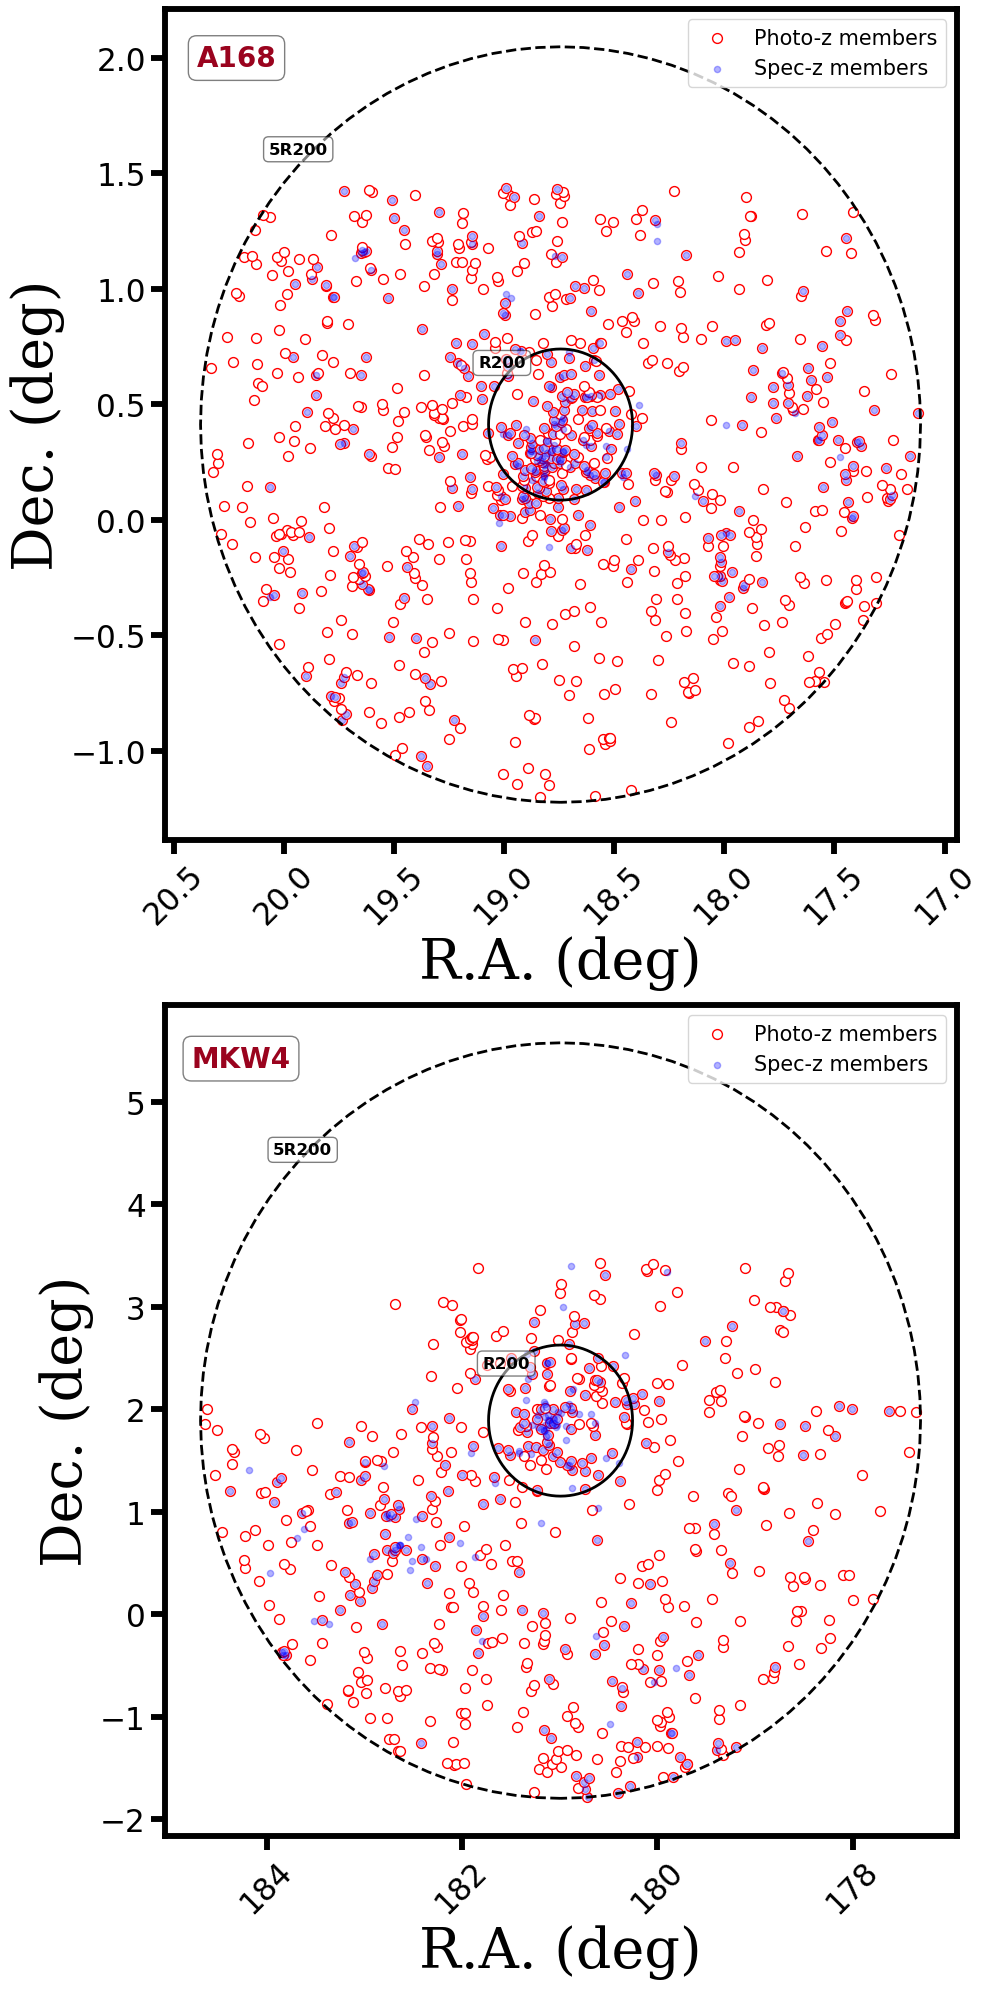

In [38]:
fig, axs = plt.subplots(2, 1, figsize=(10, 20))

for i, cluster in enumerate(["A168", "MKW4"]):

    t = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cluster))
    r_PStotal = t["r_PStotal"].values
    mask_good = ~np.isnan(r_PStotal) & (r_PStotal < r_cut)
    t_good = t[mask_good]

    spec_members = t_good["flag_member"].values == 0
    phot_members = t_good["flag_member_photz1"].values == 0


    cl = np.argwhere(clusters_properties["Cluster"] == cluster)[0][0]

    #PROPERTIES OF THE CLUSTER
    ra0 = clusters_properties["R.A."][cl]
    dec0 = clusters_properties["Dec."][cl]
    z_cluster = clusters_properties["z"][cl]
    r200_mpc = clusters_properties["R200"][cl]
    zp_bias = float(clusters_properties["off"][cl])

    kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
    r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

    print("Spec-z of cluster {}: {}".format(cluster, z_cluster))
    print("R200 (deg) for cluster {}: {}".format(cluster, r200_deg))
    print("R200 (Mpc) for cluster {}: {}".format(cluster, r200_mpc))
    print()

    ax1 = axs[i]

    ax1.scatter(t_good["ra"][phot_members], t_good["dec"][phot_members], 
                c="white", s=50, edgecolor="red", label=r"Photo-z members")

    ax1.scatter(t_good["ra"][spec_members & (t_good["R"]<5)], t_good["dec"][spec_members & (t_good["R"]<5)], c="blue", s=20, 
                alpha=0.3, label=r"Spec-z members")

    ax1.set_xlabel("R.A. (deg)", fontdict=font)
    ax1.set_ylabel("Dec. (deg)", fontdict=font)
    # ax1.scatter(ra0, dec0, marker="X", s=50, color="k", label="Cluster center")

    c0 = SkyCoord(ra=ra0, dec=dec0, frame='icrs', unit='deg')
    r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=2, edgecolor="k", facecolor="None")
    ax1.add_patch(r1)
    r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
                lw=2, edgecolor="k", facecolor="None", ls='--')
    ax1.add_patch(r2)

    # Ângulo onde o texto será colocado (em radianos)
    angulo_texto = np.pi / 4  # 45 graus

    # Ponto na borda do círculo R200
    x_r200 = ra0 + r200_deg * np.cos(angulo_texto)
    y_r200 = dec0 + r200_deg * np.sin(angulo_texto)

    # Ponto na borda do círculo 5R200
    x_5r200 = ra0 + (5 * r200_deg) * np.cos(angulo_texto)
    y_5r200 = dec0 + (5 * r200_deg) * np.sin(angulo_texto)


    # Adicionar os textos sobre os círculos (com um pequeno deslocamento radial para fora)
    deslocamento = 0.05  # ajuste este valor conforme necessidade (graus)

    ax1.text(x_r200 + deslocamento * np.cos(angulo_texto),
            y_r200 + deslocamento * np.sin(angulo_texto),
            "R200", fontsize=12, color="black", ha='center', va='center',
            bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.5), fontweight="bold")

    ax1.text(x_5r200 + deslocamento * np.cos(angulo_texto),
            y_5r200 + deslocamento * np.sin(angulo_texto),
            "5R200", fontsize=12, color="black", ha='center', va='center',
            bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.5), fontweight="bold")
    

    # Ponto para colocar nome dos aglomerados
    x_6r200 = ra0 + (6 * r200_deg) * np.cos(angulo_texto) + 0.15*r200_deg
    y_6r200 = dec0 + (6 * r200_deg) * np.sin(angulo_texto) + 0.5*r200_deg
    ax1.text(x_6r200 + deslocamento * np.cos(angulo_texto),
            y_6r200 + deslocamento * np.sin(angulo_texto),
            "{}".format(cluster), fontsize=20, color="#9a031e", ha='center', va='center',
            bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white", alpha=0.5), fontweight="bold")

    ax1.legend(fontsize=15)
    ax1.tick_params(axis='x', rotation=45)
    ax1.invert_xaxis()

    fig.tight_layout()